### Import Libraries

In [1]:
from pathlib import Path
from io import BytesIO
import json
import hashlib
import time
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pyarrow.parquet as pq
from PIL import Image
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.svm import SVC
from xgboost import XGBClassifier, XGBRegressor
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torchvision.models import efficientnet_b0

### Set Project Paths and Random Seed

In [2]:
PROJECT_DIR = Path("C:/Users/LEGION/Desktop/depi project")
INDIA_DIR = PROJECT_DIR / "processed_data" / "india_yield"
SOIL_DIR = PROJECT_DIR / "processed_data" / "soil_recommendation"
EURO_DIR = PROJECT_DIR / "processed_data" / "eurosat"
for output_dir in [INDIA_DIR, SOIL_DIR, EURO_DIR]:
    (output_dir / "figures").mkdir(parents=True, exist_ok=True)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
for model_directory in [SOIL_DIR, INDIA_DIR]:
    (model_directory / "trained_models").mkdir(exist_ok=True)

### India: Load Crop Production Data

In [3]:
INDIA_DIR.mkdir(parents=True, exist_ok=True)
india_candidates = [
    PROJECT_DIR / 'crop_production_india_cleaned.csv',
    PROJECT_DIR / 'crop_production.csv',
    PROJECT_DIR / 'crop_production.csv.zip'
]
india_source = next((india_path for india_path in india_candidates if india_path.exists()), None)
if india_source is None:
    raise FileNotFoundError('India crop production data were not found.')

if india_source.suffix == '.zip':
    with zipfile.ZipFile(india_source) as india_archive:
        india_members = [india_name for india_name in india_archive.namelist()
                         if Path(india_name).name.lower() == 'crop_production.csv']
        if len(india_members) != 1:
            raise ValueError('The ZIP must contain one crop_production.csv file.')
        with india_archive.open(india_members[0]) as india_file:
            india_raw = pd.read_csv(india_file)
else:
    india_raw = pd.read_csv(india_source)

print('Selected file:', india_source.name)
print('Original shape:', india_raw.shape)
display(india_raw.head())

Selected file: crop_production.csv.zip
Original shape: (246091, 7)


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0


### India: Inspect Missing Values and Duplicates

In [4]:
india_initial_audit = pd.DataFrame({
    'data_type': india_raw.dtypes.astype(str),
    'missing_values': india_raw.isna().sum()
})
display(india_initial_audit)
print('Duplicate rows before cleaning:', int(india_raw.duplicated().sum()))
display(india_raw.describe(include='all').T)

,data_type,missing_values
State_Name,str,0
District_Name,str,0
Crop_Year,int64,0
Season,str,0
Crop,str,0
Area,float64,0
Production,float64,3730


Duplicate rows before cleaning: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State_Name,246091,33,Uttar Pradesh,33306,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District_Name,246091,646,BIJAPUR,945,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop_Year,246091.0,NaN,NaN,NaN,2005.643018,4.952164,1997.0,2002.0,2006.0,2010.0,2015.0
Season,246091,6,Kharif,95951,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop,246091,124,Rice,15104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area,246091.0,NaN,NaN,NaN,12002.820864,50523.404019,0.04,80.0,582.0,4392.0,8580100.0
Production,242361.0,NaN,NaN,NaN,582503.442251,17065813.17241,0.0,88.0,729.0,7023.0,1250800000.0


### India: Standardize Columns and Data Types

In [5]:
india_df = india_raw.copy()
india_df.columns = india_df.columns.str.strip().str.lower().str.replace(r'\s+', '_', regex=True)
india_required = ['state_name', 'district_name', 'crop_year', 'season', 'crop', 'area', 'production']
assert set(india_required).issubset(india_df.columns)
india_df = india_df[india_required].copy()
india_df.insert(0, 'source_row_id', india_df.index)

for india_column in ['state_name', 'district_name', 'season', 'crop']:
    india_df[india_column] = (
        india_df[india_column].astype('string').str.strip()
        .str.replace(r'\s+', ' ', regex=True).replace('', pd.NA)
    )

for india_column in ['crop_year', 'area', 'production']:
    india_df[india_column] = pd.to_numeric(india_df[india_column], errors='coerce')
    india_df[india_column] = india_df[india_column].replace([np.inf, -np.inf], np.nan)

india_counts = {
    'source_rows': len(india_df),
    'production_missing_at_audit': int(india_df['production'].isna().sum())
}
print('Missing production values:', india_counts['production_missing_at_audit'])
print('Reference count stated in the project: 3,730')
display(india_df.head())

Missing production values: 3730
Reference count stated in the project: 3,730


,source_row_id,state_name,district_name,crop_year,season,crop,area,production
0,0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0


### India: Remove Invalid and Duplicate Rows

In [6]:
india_empty = india_df[india_required].isna().all(axis=1)
india_counts['empty_rows_removed'] = int(india_empty.sum())
india_df = india_df.loc[~india_empty].copy()

india_duplicates = india_df.duplicated(subset=india_required)
india_counts['duplicate_rows_removed'] = int(india_duplicates.sum())
india_df = india_df.loc[~india_duplicates].copy()

india_invalid = (
    india_df[india_required[:-1]].isna().any(axis=1)
    | (india_df['area'] < 0)
    | (india_df['production'] < 0)
    | (india_df['crop_year'] % 1 != 0)
)
india_counts['invalid_rows_removed'] = int(india_invalid.sum())
india_df = india_df.loc[~india_invalid].copy()
india_df['crop_year'] = india_df['crop_year'].astype(int)
india_df['production_was_missing'] = india_df['production'].isna()
india_df['is_coconut'] = india_df['crop'].str.casefold().eq('coconut').astype(int)
india_df = india_df.set_index('source_row_id', drop=False)

display(pd.Series(india_counts, name='Rows').to_frame())
print('Season categories:', sorted(india_df['season'].unique().tolist()))
assert india_df['season'].nunique() == 6

,Rows
source_rows,246091
production_missing_at_audit,3730
empty_rows_removed,0
duplicate_rows_removed,0
invalid_rows_removed,0


Season categories: ['Autumn', 'Kharif', 'Rabi', 'Summer', 'Whole Year', 'Winter']


### India: Check and Exclude 2015

In [7]:
india_year_audit = india_df.groupby('crop_year').agg(
    records=('crop', 'size'),
    states=('state_name', 'nunique'),
    districts=('district_name', 'nunique'),
    production_total_mixed_units=('production', 'sum')
)
india_year_units = (
    india_df.groupby(['crop_year', 'is_coconut'])['production'].sum()
    .unstack(fill_value=0)
    .rename(columns={0: 'non_coconut_production', 1: 'coconut_fruit_count'})
)
india_year_audit = india_year_audit.join(india_year_units)
display(india_year_audit.loc[india_year_audit.index >= 2011])

india_2015_rows = int((india_df['crop_year'] == 2015).sum())
india_2014_rows = int((india_df['crop_year'] == 2014).sum())
print('2015 records:', india_2015_rows)
print('2014 records:', india_2014_rows)
print('2015 / 2014 record ratio:', round(india_2015_rows / max(india_2014_rows, 1), 4))

india_year_audit.to_csv(INDIA_DIR / 'year_coverage_audit.csv')
india_counts['2015_rows_excluded'] = india_2015_rows
india_df = india_df.loc[india_df['crop_year'] != 2015].copy()
assert not (india_df['crop_year'] == 2015).any()

,records,states,districts,production_total_mixed_units,non_coconut_production,coconut_fruit_count
crop_year,,,,,,
2011,14071,25,521,1.430890e+10,7.146862e+08,1.359422e+10
2012,13410,24,517,8.171055e+09,6.766197e+08,7.494435e+09
2013,13650,24,506,1.290359e+10,6.844007e+08,1.221919e+10
2014,10973,22,427,8.664541e+09,5.967291e+08,8.067812e+09
2015,562,2,34,6.935065e+06,6.935065e+06,0.000000e+00


2015 records: 562
2014 records: 10973
2015 / 2014 record ratio: 0.0512


### India: Separate Coconut and Remove Small Areas

In [8]:
india_coconut = india_df.loc[india_df['is_coconut'] == 1].copy()
india_coconut.to_csv(INDIA_DIR / 'coconut_separate_records.csv', index=False)
india_counts['coconut_rows_separated'] = len(india_coconut)
display(
    india_coconut.groupby('state_name').agg(
        records=('crop', 'size'), fruit_count=('production', 'sum')
    ).sort_values('fruit_count', ascending=False).head(10)
)

india_df = india_df.loc[india_df['is_coconut'] == 0].copy()
india_small_area = india_df.loc[india_df['area'] < 1.0].copy()
india_small_area.to_csv(INDIA_DIR / 'excluded_area_below_1ha.csv', index=False)
india_counts['area_below_1ha_rows_removed'] = len(india_small_area)
india_df = india_df.loc[india_df['area'] >= 1.0].copy()
india_counts['eligible_modeling_rows'] = len(india_df)

display(pd.Series(india_counts, name='Rows').to_frame())
assert india_df['source_row_id'].is_unique
assert india_df['is_coconut'].eq(0).all()

,records,fruit_count
state_name,,
Kerala,252,9.780304e+10
Andhra Pradesh,169,1.680600e+10
Tamil Nadu,295,1.093774e+10
Assam,400,1.954408e+09
West Bengal,216,7.178412e+08
Andaman and Nicobar Islands,18,7.177900e+08
Goa,12,5.031126e+08
Puducherry,57,3.791390e+08
Telangana,52,1.056730e+08


,Rows
source_rows,246091
production_missing_at_audit,3730
empty_rows_removed,0
duplicate_rows_removed,0
invalid_rows_removed,0
2015_rows_excluded,562
coconut_rows_separated,1985
area_below_1ha_rows_removed,26
eligible_modeling_rows,243518


### India: Split Training, Validation and Test Data

In [9]:
india_features = ['state_name', 'district_name', 'crop_year', 'season', 'crop', 'area']
india_categorical = ['state_name', 'district_name', 'crop']
india_numeric = ['area', 'crop_year']

india_train, india_holdout = train_test_split(india_df, test_size=0.30, random_state=SEED)
india_val, india_test = train_test_split(india_holdout, test_size=0.50, random_state=SEED)
india_splits = {'train': india_train, 'val': india_val, 'test': india_test}

assert not set(india_train.index).intersection(india_val.index)
assert not set(india_train.index).intersection(india_test.index)
assert not set(india_val.index).intersection(india_test.index)
assert len(india_train) + len(india_val) + len(india_test) == len(india_df)

india_split_table = pd.DataFrame({
    india_name: {
        'rows': len(india_part),
        'fraction': len(india_part) / len(india_df),
        'missing_production': int(india_part['production'].isna().sum())
    }
    for india_name, india_part in india_splits.items()
}).T
display(india_split_table)

,rows,fraction,missing_production
train,170462.0,0.699998,2607.0
val,36528.0,0.150001,544.0
test,36528.0,0.150001,535.0


### India: Fill Missing Production and Calculate Yield

In [10]:
india_production_median = float(india_train['production'].median())
assert np.isfinite(india_production_median)
india_prepared = {}

for india_name, india_part in india_splits.items():
    india_part = india_part.copy()
    india_part['area_raw'] = india_part['area']
    india_part['production_raw'] = india_part['production']
    india_part['target_observed'] = ~india_part['production_was_missing']
    india_part['yield_observed'] = india_part['production_raw'] / india_part['area_raw']
    india_part['production'] = india_part['production'].fillna(india_production_median)
    india_part['yield'] = india_part['production'] / india_part['area']
    india_part['yield_raw'] = india_part['yield']
    india_prepared[india_name] = india_part

print('Training production median:', india_production_median)
display(pd.DataFrame({
    india_name: india_part[['production', 'yield']].isna().sum()
    for india_name, india_part in india_prepared.items()
}))

Training production median: 713.0


,train,val,test
production,0,0,0
yield,0,0,0


### India: Calculate Training IQR Limits

In [11]:
india_bounds = {}

for india_column in ['area', 'production', 'yield']:
    india_q1 = float(india_prepared['train'][india_column].quantile(0.25))
    india_q3 = float(india_prepared['train'][india_column].quantile(0.75))
    india_iqr = india_q3 - india_q1
    india_bounds[india_column] = {
        'q1': india_q1,
        'q3': india_q3,
        'iqr': india_iqr,
        'lower': india_q1 - 1.5 * india_iqr,
        'upper': india_q3 + 1.5 * india_iqr
    }

display(pd.DataFrame(india_bounds).T)

,q1,q3,iqr,lower,upper
area,80.000000,4378.000000,4298.00000,-6367.000000,10825.000000
production,90.000000,6500.000000,6410.00000,-9525.000000,16115.000000
yield,0.518036,2.420646,1.90261,-2.335879,5.274561


### India: Clip Outliers

In [12]:
india_capped = {}
india_clip_records = []

for india_name, india_part in india_prepared.items():
    india_part = india_part.copy()
    for india_column in ['area', 'production', 'yield']:
        india_lower = india_bounds[india_column]['lower']
        india_upper = india_bounds[india_column]['upper']
        india_before = india_part[india_column].copy()
        india_part[india_column] = india_before.clip(india_lower, india_upper)
        india_clip_records.append({
            'split': india_name,
            'feature': india_column,
            'values_changed': int((india_before != india_part[india_column]).sum()),
            'changed_fraction': float((india_before != india_part[india_column]).mean())
        })
    india_capped[india_name] = india_part

india_clip_audit = pd.DataFrame(india_clip_records)
display(india_clip_audit)

,split,feature,values_changed,changed_fraction
0,train,area,28117,0.164946
1,train,production,29713,0.174309
2,train,yield,26241,0.153940
3,val,area,5949,0.162861
4,val,production,6295,0.172334
5,val,yield,5676,0.155388
6,test,area,6031,0.165106
7,test,production,6257,0.171293
8,test,yield,5604,0.153417


### India: Plot Yield Before and After Clipping

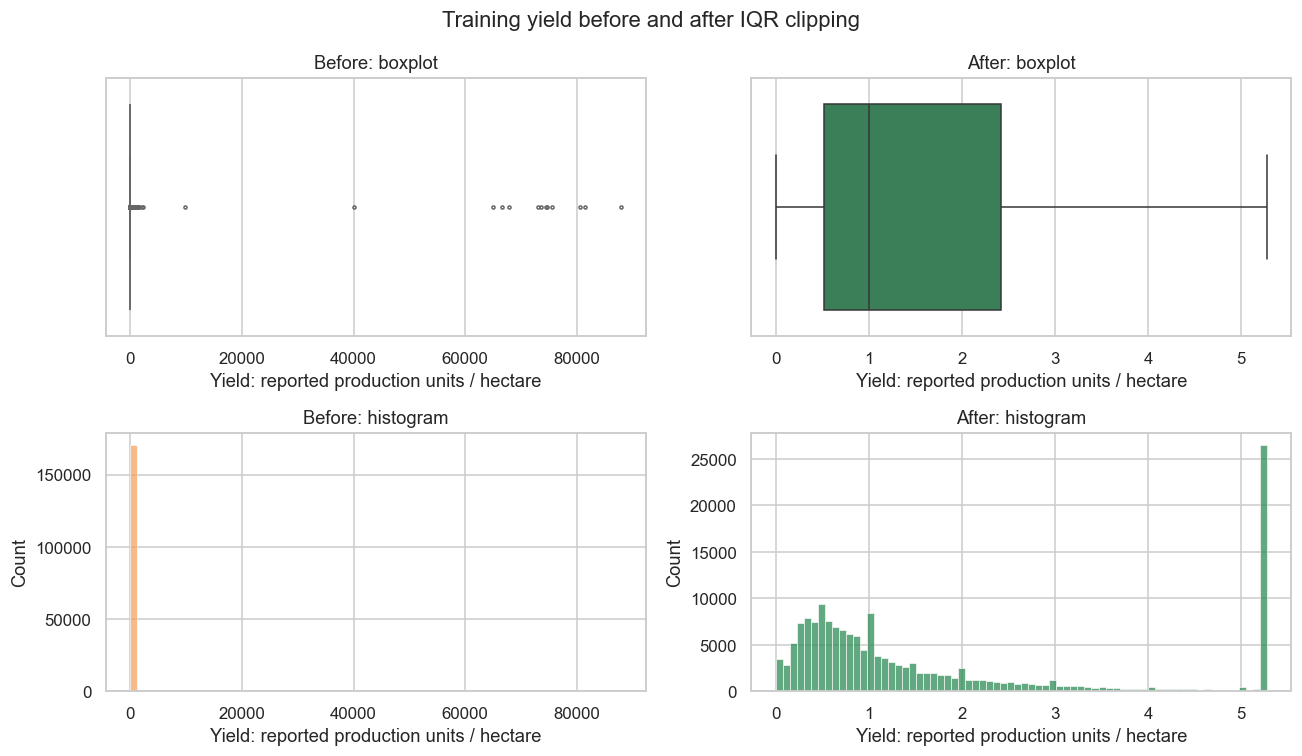

,before,after
count,170462.000000,170462.000000
mean,13.522482,1.789714
std,611.953050,1.751532
min,0.000000,0.000000
25%,0.518036,0.518036
50%,1.000000,1.000000
75%,2.420646,2.420646
max,88000.000000,5.274561


In [13]:
india_before_yield = india_prepared['train']['yield']
india_after_yield = india_capped['train']['yield']
india_figure, india_axes = plt.subplots(2, 2, figsize=(12, 7))

sns.boxplot(x=india_before_yield, ax=india_axes[0, 0], color='sandybrown', fliersize=2)
sns.boxplot(x=india_after_yield, ax=india_axes[0, 1], color='seagreen', fliersize=2)
sns.histplot(x=india_before_yield, bins=70, ax=india_axes[1, 0], color='sandybrown')
sns.histplot(x=india_after_yield, bins=70, ax=india_axes[1, 1], color='seagreen')

india_plot_titles = ['Before: boxplot', 'After: boxplot', 'Before: histogram', 'After: histogram']
for india_axis, india_title in zip(india_axes.flat, india_plot_titles):
    india_axis.set_title(india_title)
    india_axis.set_xlabel('Yield: reported production units / hectare')

india_figure.suptitle('Training yield before and after IQR clipping')
india_figure.tight_layout()
plt.show()

india_yield_statistics = pd.DataFrame({
    'before': india_before_yield.describe(),
    'after': india_after_yield.describe()
})
display(india_yield_statistics)

### India: Encode and Scale Features

In [14]:
india_x_raw = {
    india_name: india_part[india_features].copy()
    for india_name, india_part in india_capped.items()
}
india_y = {
    india_name: india_part['yield'].rename('yield')
    for india_name, india_part in india_capped.items()
}

india_preprocessor = ColumnTransformer([
    ('target', TargetEncoder(target_type='continuous', cv=5, shuffle=True, random_state=SEED),
     india_categorical),
    ('season', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['season']),
    ('numeric', StandardScaler(), india_numeric)
])

india_train_array = india_preprocessor.fit_transform(india_x_raw['train'], india_y['train'])
india_feature_names = india_preprocessor.get_feature_names_out().tolist()
india_x = {
    'train': pd.DataFrame(india_train_array, index=india_train.index, columns=india_feature_names)
}

for india_name in ['val', 'test']:
    india_array = india_preprocessor.transform(india_x_raw[india_name])
    india_x[india_name] = pd.DataFrame(
        india_array, index=india_x_raw[india_name].index, columns=india_feature_names
    )

display(india_x['train'].head())

,target__state_name,target__district_name,target__crop,season__season_Autumn,season__season_Kharif,season__season_Rabi,season__season_Summer,season__season_Whole Year,season__season_Winter,numeric__area,numeric__crop_year
source_row_id,,,,,,,,,,,
209742,1.952421,2.090474,3.058963,0.0,0.0,0.0,0.0,1.0,0.0,-0.448218,-0.329587
164684,1.400361,1.134189,0.659331,0.0,1.0,0.0,0.0,0.0,0.0,-0.099271,-0.126994
47354,1.353191,1.519310,0.539926,0.0,0.0,1.0,0.0,0.0,0.0,-0.681754,1.493747
239904,1.826489,1.566675,1.839350,0.0,0.0,0.0,0.0,1.0,0.0,-0.654627,-0.734772
72410,1.491826,1.474353,5.066742,0.0,0.0,0.0,0.0,1.0,0.0,-0.666464,-0.937364


### India: Save Processed Data

In [15]:
for india_name in ['train', 'val', 'test']:
    india_capped[india_name].to_csv(INDIA_DIR / f'prepared_{india_name}_audit.csv', index=False)
    india_x[india_name].to_csv(INDIA_DIR / f'X_{india_name}.csv', index=False)
    india_y[india_name].to_frame().to_csv(INDIA_DIR / f'y_{india_name}.csv', index=False)
    india_manifest = pd.DataFrame({
        'row_position': np.arange(len(india_x[india_name])),
        'source_row_id': india_x[india_name].index,
        'split': india_name,
        'target_observed': india_capped[india_name]['target_observed'].to_numpy()
    })
    india_manifest.to_csv(INDIA_DIR / f'split_{india_name}_manifest.csv', index=False)
    india_raw_target_columns = [
        'source_row_id', 'area_raw', 'production_raw', 'production_was_missing',
        'target_observed', 'yield_observed', 'yield_raw'
    ]
    india_capped[india_name][india_raw_target_columns].to_csv(
        INDIA_DIR / f'raw_targets_{india_name}.csv', index=False
    )

india_clip_audit.to_csv(INDIA_DIR / 'clipping_audit.csv', index=False)
india_yield_statistics.to_csv(INDIA_DIR / 'yield_before_after_statistics.csv')
print('Prepared CSV files saved in:', INDIA_DIR)

Prepared CSV files saved in: C:\Users\LEGION\Desktop\depi project\processed_data\india_yield


### India: Save Encoders and Scaler

In [16]:
joblib.dump(india_preprocessor, INDIA_DIR / 'preprocessor.joblib')
joblib.dump(india_preprocessor.named_transformers_['target'], INDIA_DIR / 'target_encoder.joblib')
joblib.dump(india_preprocessor.named_transformers_['season'], INDIA_DIR / 'season_encoder.joblib')
joblib.dump(india_preprocessor.named_transformers_['numeric'], INDIA_DIR / 'scaler.joblib')
joblib.dump(
    {'production_median': india_production_median, 'iqr_bounds': india_bounds},
    INDIA_DIR / 'cleaning_parameters.joblib'
)

india_metadata = {
    'source': str(india_source),
    'random_state': SEED,
    'input_features': india_features,
    'output_features': india_feature_names,
    'target': 'yield, independently IQR-clipped',
    'target_unit': 'reported production units per hectare; Coconut excluded',
    'production_median_train': india_production_median,
    'iqr_bounds_train': india_bounds,
    'counts': india_counts,
    'split_counts': {india_name: len(india_part) for india_name, india_part in india_x.items()},
    'target_encoding': '5-fold cross-fitting for training; full training mapping for validation/test',
    'missing_target_policy': 'training-median imputation; use target_observed for observed-target evaluation',
    'prior_imputation_provenance': 'unknown' if 'cleaned' in india_source.name else 'tracked from raw source'
}
with open(INDIA_DIR / 'metadata.json', 'w', encoding='utf-8') as india_file:
    json.dump(india_metadata, india_file, ensure_ascii=False, indent=2)
with open(INDIA_DIR / 'feature_names.json', 'w', encoding='utf-8') as india_file:
    json.dump(india_feature_names, india_file, indent=2)

print('Saved preprocessor, encoders, scaler, and preprocessing parameters.')

Saved preprocessor, encoders, scaler, and preprocessing parameters.


### Soil: Load and Inspect Data

In [17]:
soil_features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
soil_raw = pd.read_csv(PROJECT_DIR / 'Crop_recommendation (1).csv')
soil_raw.index.name = 'source_row_id'
display(soil_raw.head())
display(soil_raw.dtypes.to_frame('Data type'))
display(soil_raw.isna().sum().to_frame('Missing values'))
print('Dataset shape:', soil_raw.shape)
print('Duplicate rows:', soil_raw.duplicated().sum())
display(soil_raw[soil_features].describe().T)

,N,P,K,temperature,humidity,ph,rainfall,label
source_row_id,,,,,,,,
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


,Data type
N,int64
P,int64
K,int64
temperature,float64
humidity,float64
ph,float64
rainfall,float64
label,str


,Missing values
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


Dataset shape: (2200, 8)
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


### Soil: Clean Data

In [18]:
soil_df = soil_raw.dropna(how='all').drop_duplicates().copy()
assert soil_df[soil_features + ['label']].notna().all().all()
assert np.isfinite(soil_df[soil_features].to_numpy()).all()
assert soil_df['label'].nunique() == 22
assert soil_df['humidity'].between(0, 100).all()
assert soil_df['ph'].between(0, 14).all()
assert (soil_df[['N', 'P', 'K', 'rainfall']] >= 0).all().all()
print('Rows retained:', len(soil_df))
print('Number of crop classes:', soil_df['label'].nunique())

Rows retained: 2200
Number of crop classes: 22


### Soil: Plot Class Distribution

,Records
label,
apple,100
banana,100
blackgram,100
chickpea,100
coconut,100
coffee,100
cotton,100
grapes,100
jute,100


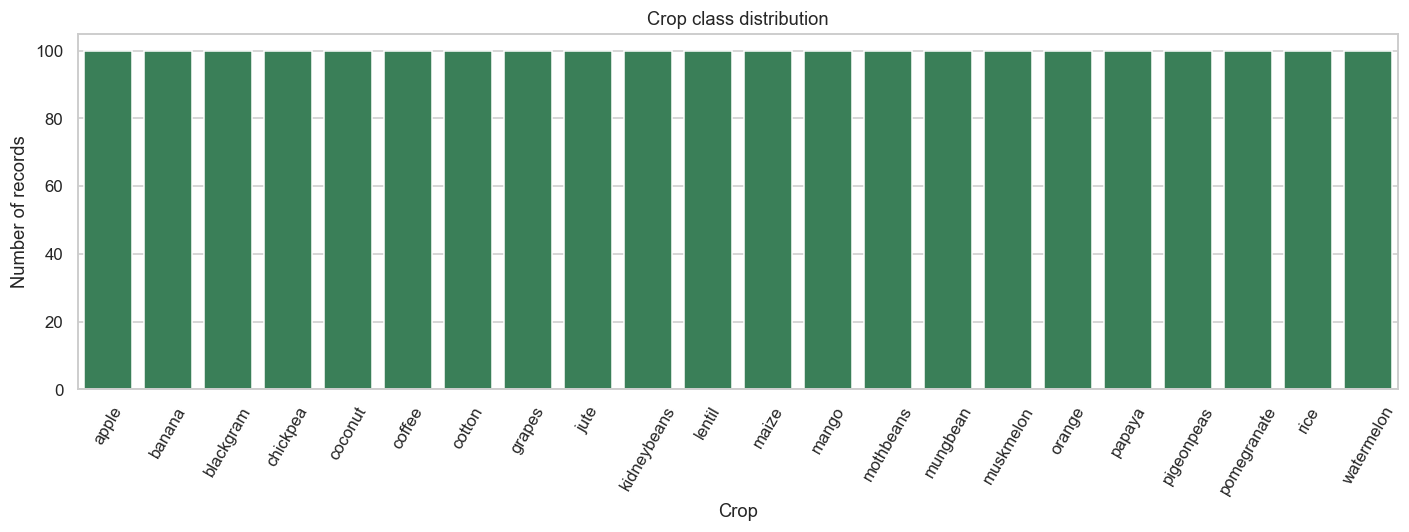

In [19]:
soil_class_counts = soil_df['label'].value_counts().sort_index()
display(soil_class_counts.to_frame('Records'))
soil_fig, soil_ax = plt.subplots(figsize=(13, 5))
sns.countplot(data=soil_df, x='label', order=soil_class_counts.index,
              color='seagreen', ax=soil_ax)
soil_ax.set(title='Crop class distribution', xlabel='Crop', ylabel='Number of records')
soil_ax.tick_params(axis='x', rotation=60)
soil_fig.tight_layout()
plt.show()

### Soil: Plot Correlation Heatmap

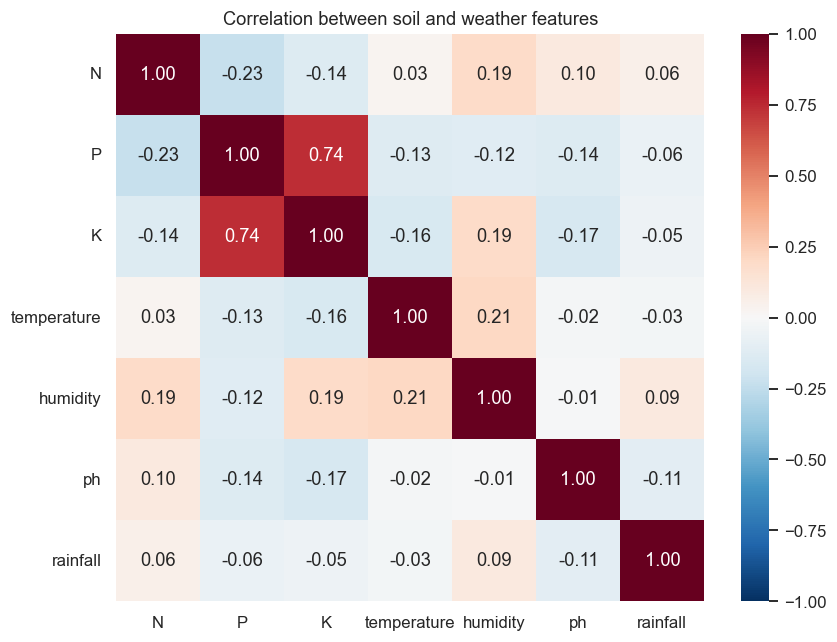

In [20]:
soil_fig, soil_ax = plt.subplots(figsize=(8, 6))
sns.heatmap(soil_df[soil_features].corr(), annot=True, fmt='.2f',
            cmap='RdBu_r', vmin=-1, vmax=1, center=0, ax=soil_ax)
soil_ax.set_title('Correlation between soil and weather features')
soil_fig.tight_layout()
plt.show()

### Soil: Plot Feature Boxplots

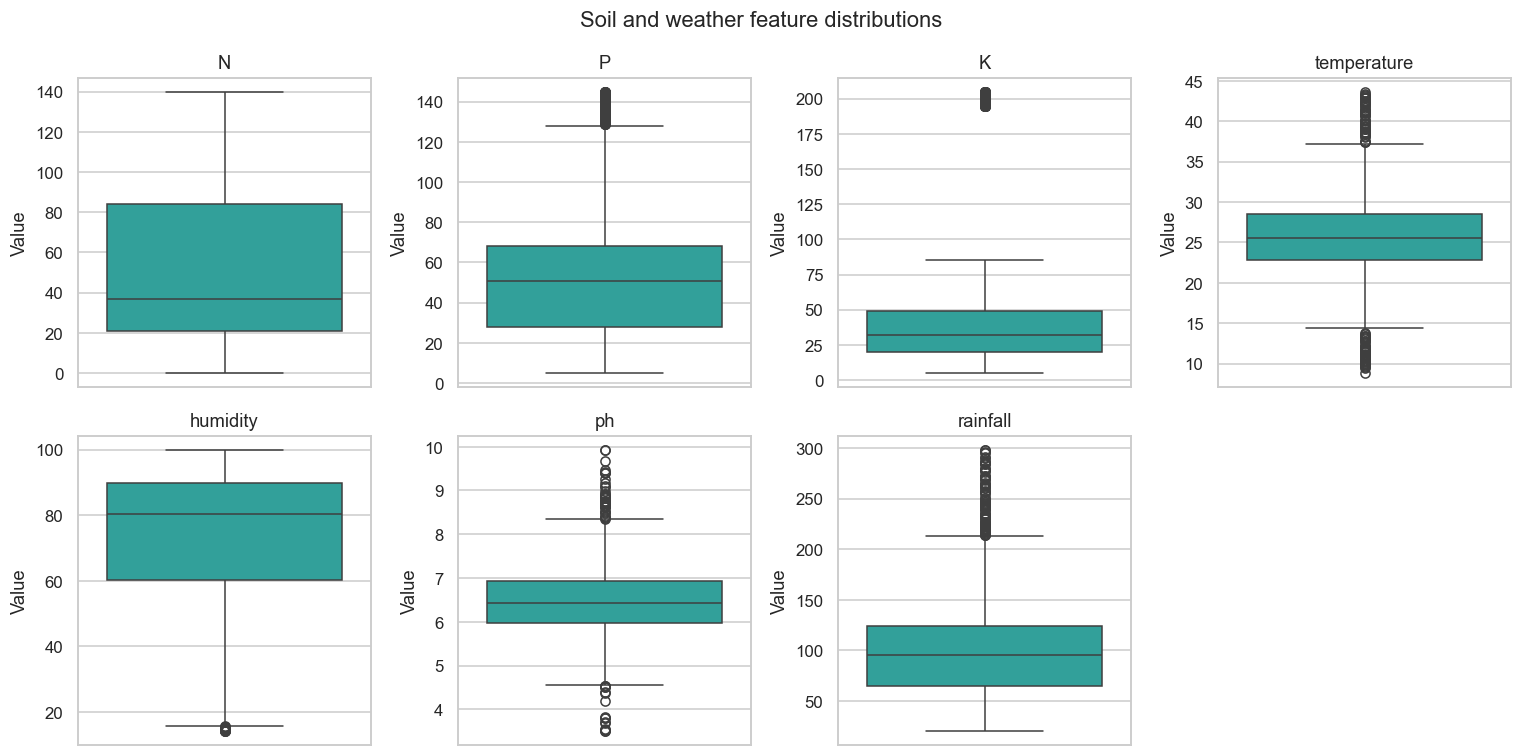

In [21]:
soil_fig, soil_axes = plt.subplots(2, 4, figsize=(14, 7))
for soil_ax, soil_feature in zip(soil_axes.flat, soil_features):
    sns.boxplot(y=soil_df[soil_feature], color='lightseagreen', ax=soil_ax)
    soil_ax.set(title=soil_feature, ylabel='Value')
soil_axes.flat[-1].axis('off')
soil_fig.suptitle('Soil and weather feature distributions')
soil_fig.tight_layout()
plt.show()

### Soil: Create Stratified Data Splits

In [22]:
soil_X = soil_df[soil_features].copy()
soil_y_text = soil_df['label'].copy()
soil_X_train_raw, soil_X_temp, soil_y_train_text, soil_y_temp = train_test_split(
    soil_X, soil_y_text, test_size=0.30, stratify=soil_y_text, random_state=SEED
)
soil_X_val_raw, soil_X_test_raw, soil_y_val_text, soil_y_test_text = train_test_split(
    soil_X_temp, soil_y_temp, test_size=0.50, stratify=soil_y_temp, random_state=SEED
)
soil_raw_splits = {'train': soil_X_train_raw, 'val': soil_X_val_raw, 'test': soil_X_test_raw}
soil_text_targets = {'train': soil_y_train_text, 'val': soil_y_val_text, 'test': soil_y_test_text}
soil_sizes = pd.Series({soil_name: len(soil_frame) for soil_name, soil_frame in soil_raw_splits.items()})
display(pd.DataFrame({'Rows': soil_sizes, 'Fraction': soil_sizes / len(soil_df)}))
display(pd.DataFrame({soil_name: soil_target.value_counts()
                      for soil_name, soil_target in soil_text_targets.items()}).sort_index())

,Rows,Fraction
train,1540,0.70
val,330,0.15
test,330,0.15


,train,val,test
label,,,
apple,70,15,15
banana,70,15,15
blackgram,70,15,15
chickpea,70,15,15
coconut,70,15,15
coffee,70,15,15
cotton,70,15,15
grapes,70,15,15
jute,70,15,15


### Soil: Encode Crop Labels

In [23]:
soil_label_encoder = LabelEncoder()
soil_label_encoder.fit(soil_y_train_text)
soil_class_to_idx = {soil_name: int(soil_idx)
                     for soil_idx, soil_name in enumerate(soil_label_encoder.classes_)}
soil_idx_to_class = {str(soil_idx): soil_name for soil_name, soil_idx in soil_class_to_idx.items()}
soil_y_splits = {}
for soil_name, soil_target in soil_text_targets.items():
    soil_y_splits[soil_name] = pd.Series(soil_label_encoder.transform(soil_target),
                                        index=soil_target.index, name='label')
    assert np.array_equal(soil_label_encoder.inverse_transform(soil_y_splits[soil_name]),
                          soil_target.to_numpy())
assert set(soil_class_to_idx.values()) == set(range(22))
display(pd.DataFrame(soil_class_to_idx.items(), columns=['Crop', 'Encoded label']))

,Crop,Encoded label
0,apple,0
1,banana,1
2,blackgram,2
3,chickpea,3
4,coconut,4
5,coffee,5
6,cotton,6
7,grapes,7
8,jute,8
9,kidneybeans,9


### Soil: Scale Features

In [24]:
soil_scaler = StandardScaler()
soil_X_train = pd.DataFrame(soil_scaler.fit_transform(soil_X_train_raw),
                             columns=soil_features, index=soil_X_train_raw.index)
soil_X_val = pd.DataFrame(soil_scaler.transform(soil_X_val_raw),
                           columns=soil_features, index=soil_X_val_raw.index)
soil_X_test = pd.DataFrame(soil_scaler.transform(soil_X_test_raw),
                            columns=soil_features, index=soil_X_test_raw.index)
soil_X_splits = {'train': soil_X_train, 'val': soil_X_val, 'test': soil_X_test}
assert soil_scaler.n_samples_seen_ == len(soil_X_train_raw)
assert np.allclose(soil_scaler.mean_, soil_X_train_raw.mean())
assert np.allclose(soil_X_train.mean(), 0, atol=1e-10)
assert np.allclose(soil_X_train.std(ddof=0), 1, atol=1e-10)
for soil_name, soil_frame in soil_X_splits.items():
    assert np.isfinite(soil_frame.to_numpy()).all()
    assert soil_frame.index.equals(soil_y_splits[soil_name].index)
display(soil_X_train.head())
display(pd.DataFrame({'Scaled mean': soil_X_train.mean(),
                      'Scaled standard deviation': soil_X_train.std(ddof=0)}))

,N,P,K,temperature,humidity,ph,rainfall
source_row_id,,,,,,,
864,-1.335936,0.417499,-0.535091,0.378274,-0.489416,0.105457,-1.006138
1090,1.797538,0.874355,-0.061709,-0.056432,0.352421,-1.102431,0.037615
304,-1.308923,0.234757,-0.554816,-0.672000,-2.173304,-0.662710,-0.486121
391,-0.282441,0.752527,-0.554816,-1.248506,-2.271540,-1.031842,-0.422218
1686,-1.173860,-1.013983,-0.712610,-1.765899,1.047107,0.007107,0.121738


,Scaled mean,Scaled standard deviation
N,4.844610e-17,1.0
P,5.075305e-17,1.0
K,2.999044e-17,1.0
temperature,3.644992e-16,1.0
humidity,-1.372639e-16,1.0
ph,-9.588290e-16,1.0
rainfall,-9.227828e-17,1.0


### Soil: Save Data, Scaler and Label Encoder

In [25]:
SOIL_DIR.mkdir(parents=True, exist_ok=True)
for soil_name in soil_X_splits:
    soil_X_splits[soil_name].to_csv(SOIL_DIR / f'X_{soil_name}.csv', index=False)
    soil_y_splits[soil_name].to_csv(SOIL_DIR / f'y_{soil_name}.csv', index=False)
joblib.dump(soil_scaler, SOIL_DIR / 'standard_scaler.joblib')
joblib.dump(soil_label_encoder, SOIL_DIR / 'label_encoder.joblib')
soil_mapping = {'class_to_idx': soil_class_to_idx, 'idx_to_class': soil_idx_to_class,
                'classes': soil_label_encoder.classes_.tolist()}
with (SOIL_DIR / 'class_mapping.json').open('w', encoding='utf-8') as soil_file:
    json.dump(soil_mapping, soil_file, indent=2)
print('Saved training, validation and test files to:', SOIL_DIR)

Saved training, validation and test files to: C:\Users\LEGION\Desktop\depi project\processed_data\soil_recommendation


### Soil: Save Split Indices

In [26]:
soil_manifest_parts = []
for soil_name, soil_frame in soil_X_splits.items():
    soil_part = pd.DataFrame({
        'split': soil_name,
        'csv_row': np.arange(len(soil_frame)),
        'source_row_id': soil_frame.index.to_numpy(),
        'label': soil_text_targets[soil_name].to_numpy(),
        'encoded_label': soil_y_splits[soil_name].to_numpy()
    })
    soil_manifest_parts.append(soil_part)
soil_manifest = pd.concat(soil_manifest_parts, ignore_index=True)
assert soil_manifest['source_row_id'].is_unique
soil_manifest.to_csv(SOIL_DIR / 'split_manifest.csv', index=False)
display(soil_manifest.head())

,split,csv_row,source_row_id,label,encoded_label
0,train,0,864,lentil,10
1,train,1,1090,banana,1
2,train,2,304,kidneybeans,9
3,train,3,391,kidneybeans,9
4,train,4,1686,orange,16


### EuroSAT: Load Images and Labels

In [27]:
euro_sources = {
    "train": "train-00000-of-00001.parquet",
    "validation": "validation-00000-of-00001.parquet",
    "test": "test-00000-of-00001.parquet"
}
euro_frames = []
euro_source_records = []
for euro_source_split, euro_filename in euro_sources.items():
    euro_path = PROJECT_DIR / euro_filename
    euro_parquet = pq.ParquetFile(euro_path)
    euro_metadata = json.loads(euro_parquet.schema_arrow.metadata[b"huggingface"])
    euro_names = euro_metadata["info"]["features"]["label"]["names"]
    if euro_frames:
        assert euro_names == euro_class_names
    euro_class_names = euro_names
    euro_frame = pd.read_parquet(euro_path)
    euro_sizes = [euro_parquet.metadata.row_group(i).num_rows for i in range(euro_parquet.num_row_groups)]
    euro_frame["source_file"] = euro_filename
    euro_frame["source_split"] = euro_source_split
    euro_frame["source_row_index"] = np.arange(len(euro_frame))
    euro_frame["source_row_group"] = np.repeat(np.arange(len(euro_sizes)), euro_sizes)
    euro_frame["source_row_in_group"] = np.concatenate([np.arange(size) for size in euro_sizes])
    euro_frames.append(euro_frame)
    euro_source_records.append({
        "source_file": euro_filename, "rows": len(euro_frame),
        "sha256": hashlib.sha256(euro_path.read_bytes()).hexdigest()
    })
euro_data = pd.concat(euro_frames, ignore_index=True)
euro_image_bytes = euro_data["image"].apply(lambda image: image["bytes"]).tolist()
euro_data = euro_data.drop(columns="image")
euro_data["image_index"] = np.arange(len(euro_data))
display(pd.DataFrame(euro_source_records)[["source_file", "rows"]])
print("Number of images:", len(euro_data))

,source_file,rows
0,train-00000-of-00001.parquet,16200
1,validation-00000-of-00001.parquet,5400
2,test-00000-of-00001.parquet,5400


Number of images: 27000


### EuroSAT: Define Classes and Suitability Mapping

In [28]:
euro_class_to_idx = dict(zip(euro_class_names, range(len(euro_class_names))))
euro_idx_to_class = {value: key for key, value in euro_class_to_idx.items()}
euro_suitability_map = {
    "AnnualCrop": 1, "Forest": 0, "HerbaceousVegetation": 1,
    "Highway": 0, "Industrial": 0, "Pasture": 1,
    "PermanentCrop": 1, "Residential": 0, "River": 0, "SeaLake": 0
}
assert set(euro_class_names) == set(euro_suitability_map)
euro_data["class_name"] = euro_data["label"].map(euro_idx_to_class)
euro_data["suitable"] = euro_data["class_name"].map(euro_suitability_map)
euro_mapping_table = pd.DataFrame({
    "class_name": euro_class_names,
    "class_index": range(len(euro_class_names)),
    "suitable": [euro_suitability_map[name] for name in euro_class_names]
})
display(euro_mapping_table)

,class_name,class_index,suitable
0,AnnualCrop,0,1
1,Forest,1,0
2,HerbaceousVegetation,2,1
3,Highway,3,0
4,Industrial,4,0
5,Pasture,5,1
6,PermanentCrop,6,1
7,Residential,7,0
8,River,8,0
9,SeaLake,9,0


### EuroSAT: Check Image Quality and Duplicates

In [29]:
euro_image_audit = []
for euro_bytes in euro_image_bytes:
    with Image.open(BytesIO(euro_bytes)) as euro_image:
        euro_image.load()
        euro_image_audit.append({
            "width": euro_image.width,
            "height": euro_image.height,
            "mode": euro_image.mode,
            "encoded_sha256": hashlib.sha256(euro_bytes).hexdigest(),
            "pixel_sha256": hashlib.sha256(euro_image.convert("RGB").tobytes()).hexdigest()
        })
euro_data = pd.concat([euro_data, pd.DataFrame(euro_image_audit)], axis=1)
assert euro_data["mode"].eq("RGB").all()
assert euro_data["width"].eq(64).all() and euro_data["height"].eq(64).all()
euro_duplicate_counts = euro_data[["image_id", "encoded_sha256", "pixel_sha256"]].apply(
    lambda column: column.duplicated().sum()
)
assert euro_duplicate_counts.eq(0).all()
display(euro_duplicate_counts.to_frame("duplicate_count"))
display(euro_data[["width", "height", "mode"]].value_counts().to_frame("images"))

,duplicate_count
image_id,0
encoded_sha256,0
pixel_sha256,0


,,,images
width,height,mode,
64,64,RGB,27000


### EuroSAT: Plot Class Distribution

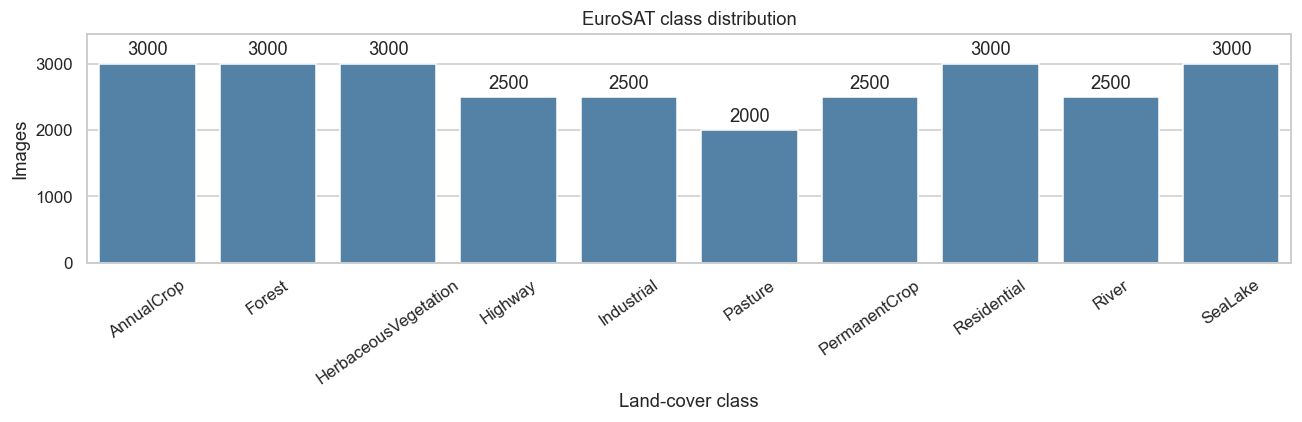

In [30]:
euro_class_counts = euro_data["class_name"].value_counts().reindex(euro_class_names)
fig, ax = plt.subplots(figsize=(12, 4))
sns.barplot(x=euro_class_counts.index, y=euro_class_counts.values, color="steelblue", ax=ax)
ax.set(title="EuroSAT class distribution", xlabel="Land-cover class", ylabel="Images")
ax.tick_params(axis="x", rotation=35)
ax.bar_label(ax.containers[0], padding=3)
ax.set_ylim(0, euro_class_counts.max() * 1.15)
fig.tight_layout()
fig.savefig(EURO_DIR / "figures" / "class_distribution.png", bbox_inches="tight")
plt.show()

### EuroSAT: Display Sample Images

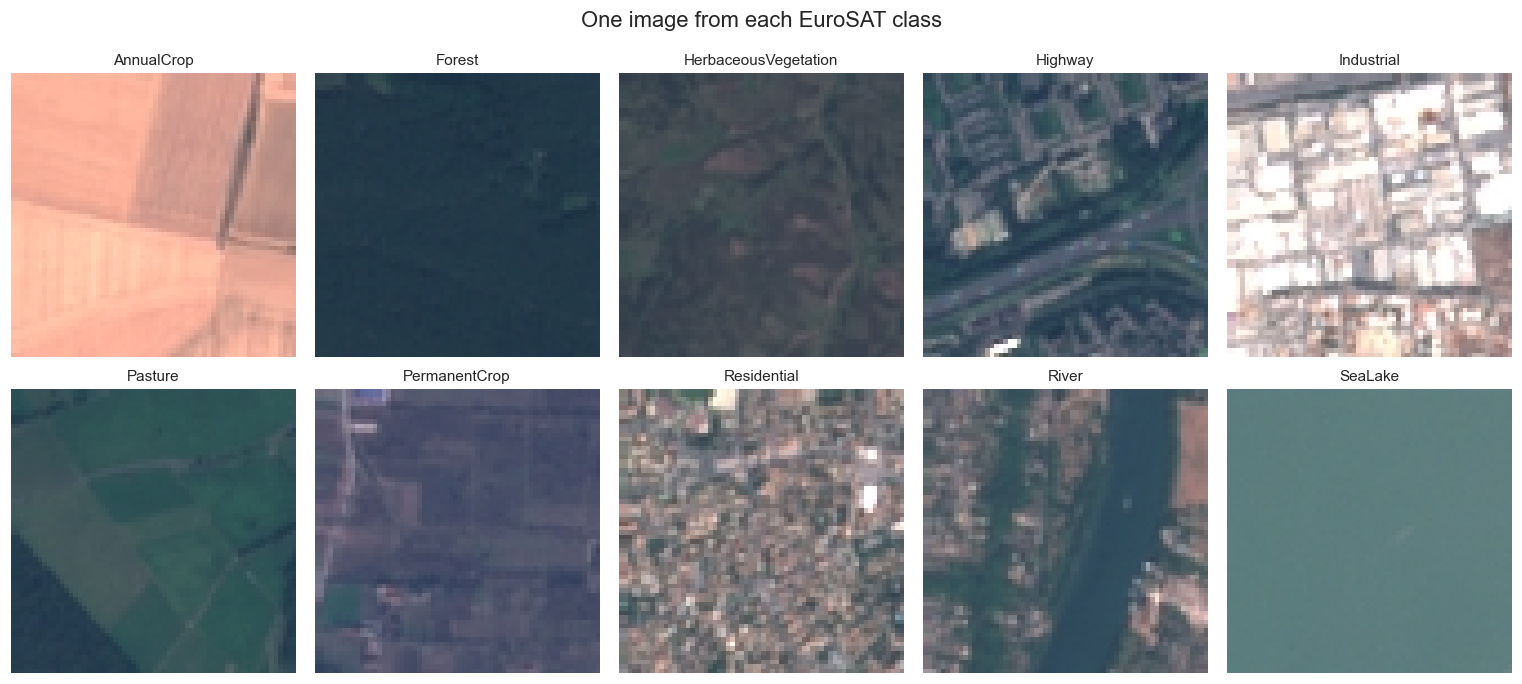

In [31]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6.5))
for ax, euro_class in zip(axes.flat, euro_class_names):
    euro_sample = euro_data[euro_data["class_name"] == euro_class].sample(1, random_state=SEED).iloc[0]
    with Image.open(BytesIO(euro_image_bytes[int(euro_sample["image_index"])])) as euro_image:
        ax.imshow(euro_image.convert("RGB"))
    ax.set_title(euro_class, fontsize=10)
    ax.axis("off")
fig.suptitle("One image from each EuroSAT class")
fig.tight_layout()
fig.savefig(EURO_DIR / "figures" / "sample_grid.png", bbox_inches="tight")
plt.show()

### EuroSAT: Create Stratified Data Splits

In [32]:
euro_train, euro_remaining = train_test_split(
    euro_data, train_size=0.70, stratify=euro_data["label"], random_state=SEED
)
euro_val, euro_test = train_test_split(
    euro_remaining, test_size=0.50, stratify=euro_remaining["label"], random_state=SEED
)
euro_splits = {"train": euro_train, "val": euro_val, "test": euro_test}
for euro_name in euro_splits:
    euro_splits[euro_name] = euro_splits[euro_name].copy().reset_index(drop=True)
    euro_splits[euro_name]["split"] = euro_name
assert set(euro_train["image_id"]).isdisjoint(euro_val["image_id"])
assert set(euro_train["image_id"]).isdisjoint(euro_test["image_id"])
assert set(euro_val["image_id"]).isdisjoint(euro_test["image_id"])
assert sum(len(part) for part in euro_splits.values()) == len(euro_data)
euro_split_counts = pd.DataFrame({
    name: part["class_name"].value_counts() for name, part in euro_splits.items()
}).reindex(euro_class_names)
display(euro_split_counts)
display(pd.DataFrame({"split": list(euro_splits), "images": [len(part) for part in euro_splits.values()]}))

,train,val,test
class_name,,,
AnnualCrop,2100,450,450
Forest,2100,450,450
HerbaceousVegetation,2100,450,450
Highway,1750,375,375
Industrial,1750,375,375
Pasture,1400,300,300
PermanentCrop,1750,375,375
Residential,2100,450,450
River,1750,375,375


,split,images
0,train,18900
1,val,4050
2,test,4050


### EuroSAT: Define Image Transformations

In [33]:
def euro_transforms(image_size=64, training=False, normalization="unit"):
    operations = [transforms.Resize((image_size, image_size))]
    if training:
        operations.extend([
            transforms.RandomHorizontalFlip(),
            transforms.RandomVerticalFlip(),
            transforms.RandomRotation(20, interpolation=InterpolationMode.BILINEAR),
            transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02)
        ])
    operations.append(transforms.ToTensor())
    if normalization == "imagenet":
        operations.append(transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        ))
    return transforms.Compose(operations)

### EuroSAT: Create Image Dataset

In [34]:
class EuroSATDataset(Dataset):
    def __init__(self, frame, image_bytes, transform, target="label"):
        self.frame = frame.reset_index(drop=True)
        self.image_bytes = image_bytes
        self.transform = transform
        self.target = target

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image_data = self.image_bytes[int(row["image_index"])]
        with Image.open(BytesIO(image_data)) as image:
            image = image.convert("RGB")
            image = self.transform(image)
        label = torch.tensor(int(row[self.target]), dtype=torch.long)
        return image, label

### EuroSAT: Create 64 x 64 DataLoaders

In [35]:
euro_datasets64 = {}
euro_loaders64 = {}
euro_batch_results = []
for euro_name, euro_part in euro_splits.items():
    euro_datasets64[euro_name] = EuroSATDataset(
        euro_part, euro_image_bytes,
        euro_transforms(64, training=(euro_name == "train"))
    )
    euro_loaders64[euro_name] = DataLoader(
        euro_datasets64[euro_name], batch_size=32,
        shuffle=(euro_name == "train"), num_workers=0,
        generator=torch.Generator().manual_seed(SEED)
    )
    euro_images, euro_labels = next(iter(euro_loaders64[euro_name]))
    assert euro_images.shape == (32, 3, 64, 64)
    assert euro_images.dtype == torch.float32 and euro_labels.dtype == torch.long
    assert torch.isfinite(euro_images).all()
    assert 0 <= euro_images.min() and euro_images.max() <= 1
    euro_batch_results.append({"split": euro_name, "batch_shape": str(tuple(euro_images.shape))})
for euro_name in ["val", "test"]:
    assert torch.equal(euro_datasets64[euro_name][0][0], euro_datasets64[euro_name][0][0])
display(pd.DataFrame(euro_batch_results))

,split,batch_shape
0,train,"(32, 3, 64, 64)"
1,val,"(32, 3, 64, 64)"
2,test,"(32, 3, 64, 64)"


### EuroSAT: Display Augmented Images

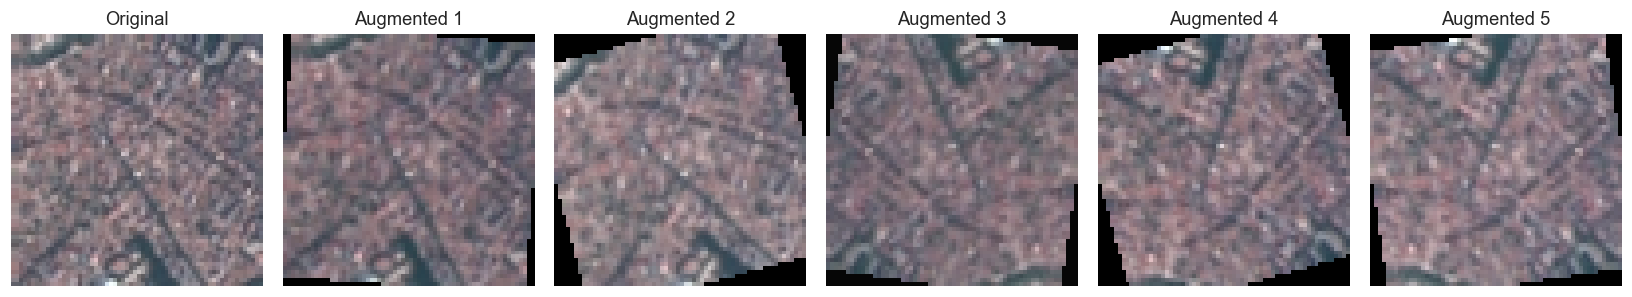

In [36]:
euro_example = euro_splits["train"].iloc[0]
with Image.open(BytesIO(euro_image_bytes[int(euro_example["image_index"])])) as euro_image:
    euro_original = euro_image.convert("RGB")
euro_augmentation = euro_transforms(64, training=True)
torch.manual_seed(SEED)
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(euro_original)
axes[0].set_title("Original")
for i in range(1, 6):
    euro_augmented = euro_augmentation(euro_original)
    axes[i].imshow(euro_augmented.permute(1, 2, 0).numpy())
    axes[i].set_title(f"Augmented {i}")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(EURO_DIR / "figures" / "augmentation_preview.png", bbox_inches="tight")
plt.show()

### EuroSAT: Create 224 x 224 DataLoaders

In [37]:
euro_loaders224 = {}
euro_transfer_results = []
euro_mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
euro_std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
for euro_name, euro_part in euro_splits.items():
    euro_dataset = EuroSATDataset(
        euro_part, euro_image_bytes,
        euro_transforms(224, training=(euro_name == "train"), normalization="imagenet"),
        target="suitable"
    )
    euro_loaders224[euro_name] = DataLoader(
        euro_dataset, batch_size=16, shuffle=(euro_name == "train"), num_workers=0
    )
    euro_images, euro_labels = next(iter(euro_loaders224[euro_name]))
    euro_restored = euro_images * euro_std + euro_mean
    assert euro_images.shape == (16, 3, 224, 224)
    assert torch.isfinite(euro_images).all()
    assert set(euro_labels.tolist()).issubset({0, 1})
    assert euro_restored.min() >= -0.00001 and euro_restored.max() <= 1.00001
    euro_transfer_results.append({"split": euro_name, "batch_shape": str(tuple(euro_images.shape))})
display(pd.DataFrame(euro_transfer_results))

,split,batch_shape
0,train,"(16, 3, 224, 224)"
1,val,"(16, 3, 224, 224)"
2,test,"(16, 3, 224, 224)"


### EuroSAT: Save Splits and Class Mappings

In [38]:
for euro_name, euro_part in euro_splits.items():
    euro_part.to_csv(EURO_DIR / f"{euro_name}_manifest.csv", index=False)
    euro_saved = pd.read_csv(EURO_DIR / f"{euro_name}_manifest.csv")
    assert euro_saved["image_id"].tolist() == euro_part["image_id"].tolist()
euro_data.to_csv(EURO_DIR / "all_images_manifest.csv", index=False)
euro_split_counts.to_csv(EURO_DIR / "class_split_counts.csv")
pd.DataFrame(euro_source_records).to_csv(EURO_DIR / "source_audit.csv", index=False)
for euro_filename, euro_mapping in [
    ("class_to_idx.json", euro_class_to_idx),
    ("idx_to_class.json", euro_idx_to_class),
    ("suitability_map.json", euro_suitability_map)
]:
    (EURO_DIR / euro_filename).write_text(json.dumps(euro_mapping, indent=2), encoding="utf-8")
euro_config = {
    "random_state": SEED, "source_root_relative_to_output": "../..",
    "source_files": euro_source_records,
    "manifest_files": {name: f"{name}_manifest.csv" for name in euro_splits},
    "image_sizes": [64, 224], "normalization": ["unit", "imagenet"],
    "augmentation_train_only": True, "rotation_degrees": 20,
    "rotation_interpolation": "bilinear", "resize_interpolation": "bilinear",
    "suitability_semantics": "Project-defined land-cover proxy",
    "notebook": "depiProject.ipynb"
}
(EURO_DIR / "pipeline_config.json").write_text(json.dumps(euro_config, indent=2), encoding="utf-8")
print("EuroSAT preprocessing completed.")

EuroSAT preprocessing completed.


### Define Evaluation Metrics

In [39]:
def classification_metrics(y_true, y_pred):
    result = {"Accuracy": accuracy_score(y_true, y_pred)}
    for average in ["macro", "weighted"]:
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, average=average, zero_division=0
        )
        result[f"Precision_{average}"] = precision
        result[f"Recall_{average}"] = recall
        result[f"F1_{average}"] = f1
    return result

def regression_metrics(y_true, y_pred):
    return {
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

### EuroSAT: Load Training Data

In [40]:
torch.set_num_threads(3)
torch.manual_seed(SEED)
vision_manifests = {name: pd.read_csv(EURO_DIR / f"{name}_manifest.csv")
                    for name in ["train", "val", "test"]}
vision_class_to_idx = json.loads((EURO_DIR / "class_to_idx.json").read_text(encoding="utf-8"))
vision_suitability_map = json.loads((EURO_DIR / "suitability_map.json").read_text(encoding="utf-8"))
vision_classes = sorted(vision_class_to_idx, key=vision_class_to_idx.get)
vision_images = {}
for vision_filename in vision_manifests["train"]["source_file"].unique():
    vision_frame = pd.read_parquet(PROJECT_DIR / vision_filename, columns=["image"])
    for vision_row_index, vision_image in enumerate(vision_frame["image"]):
        vision_images[(vision_filename, vision_row_index)] = vision_image["bytes"]
vision_cache = EURO_DIR / "frozen_features"
vision_cache.mkdir(exist_ok=True)
assert set(vision_manifests["train"]["image_id"]).isdisjoint(vision_manifests["val"]["image_id"])
assert set(vision_manifests["train"]["image_id"]).isdisjoint(vision_manifests["test"]["image_id"])
display(pd.Series({name: len(frame) for name, frame in vision_manifests.items()}, name="Images").to_frame())
print("Training device: CPU; pretrained frozen EfficientNet-B0")

,Images
train,18900
val,4050
test,4050


Training device: CPU; pretrained frozen EfficientNet-B0


### EuroSAT: Build Transfer Learning Model

In [41]:
vision_weights_path = EURO_DIR / "weights" / "efficientnet_b0_imagenet.pth"
vision_weights_hash = hashlib.sha256(vision_weights_path.read_bytes()).hexdigest()
assert vision_weights_hash.startswith("7f5810bc")
vision_model = efficientnet_b0(weights=None)
vision_model.load_state_dict(torch.load(vision_weights_path, map_location="cpu", weights_only=True))
for vision_parameter in vision_model.parameters():
    vision_parameter.requires_grad = False
vision_model.classifier = nn.Sequential(
    nn.LayerNorm(1280), nn.Linear(1280, 256), nn.ReLU(),
    nn.Dropout(0.3), nn.Linear(256, 10)
)
vision_model = vision_model.to(memory_format=torch.channels_last)
vision_backbone = nn.Sequential(vision_model.features, vision_model.avgpool, nn.Flatten())
vision_backbone.eval()
print("Trainable parameters:", sum(p.numel() for p in vision_model.parameters() if p.requires_grad))
print("Output classes:", len(vision_classes))
display(vision_model.classifier)

Trainable parameters: 333066
Output classes: 10


Sequential(
  (0): LayerNorm((1280,), eps=1e-05, elementwise_affine=True, bias=True)
  (1): Linear(in_features=1280, out_features=256, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=256, out_features=10, bias=True)
)

### EuroSAT: Create Training Dataset

In [42]:
class TrainingImageDataset(Dataset):
    def __init__(self, manifest, images, transform):
        self.rows = manifest.reset_index(drop=True)
        self.images = images
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        key = (row["source_file"], int(row["source_row_index"]))
        with Image.open(BytesIO(self.images[key])) as image:
            tensor = self.transform(image.convert("RGB"))
        return tensor, int(row["label"])

### EuroSAT: Define Training Transformations

In [43]:
def training_image_transform(augment=False):
    steps = [transforms.Resize((224, 224))]
    if augment:
        steps.extend([
            transforms.RandomHorizontalFlip(),
            transforms.RandomVerticalFlip(),
            transforms.RandomRotation(20, interpolation=InterpolationMode.BILINEAR),
            transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02)
        ])
    steps.extend([
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    return transforms.Compose(steps)

### EuroSAT: Extract and Cache Image Features

In [44]:
def extract_frozen_features(backbone, manifest, image_store, cache_dir, name, augment=False):
    ids = manifest[["image_id", "label", "source_file", "source_row_index", "pixel_sha256"]].to_json(orient="records")
    settings = {"ids": ids, "size": 224, "augment": augment, "seed": 42, "weights": "7f5810bc"}
    signature = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()
    array_path = cache_dir / f"{name}.npz"
    info_path = cache_dir / f"{name}.json"
    if array_path.exists() and info_path.exists():
        info = json.loads(info_path.read_text(encoding="utf-8"))
        if info["signature"] == signature:
            saved = np.load(array_path)
            assert np.array_equal(saved["labels"], manifest["label"].to_numpy())
            assert saved["features"].shape == (len(manifest), 1280)
            print(f"{name}: loaded {len(manifest):,} cached frozen feature vectors", flush=True)
            return torch.from_numpy(saved["features"]), torch.from_numpy(saved["labels"])
    torch.manual_seed(42)
    dataset = TrainingImageDataset(manifest, image_store, training_image_transform(augment))
    loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)
    feature_parts, label_parts = [], []
    start = time.perf_counter()
    backbone.eval()
    with torch.no_grad():
        for batch_index, (images, labels) in enumerate(loader):
            images = images.contiguous(memory_format=torch.channels_last)
            feature_parts.append(backbone(images).cpu())
            label_parts.append(labels)
            if (batch_index + 1) % 100 == 0 or batch_index + 1 == len(loader):
                print(f"{name}: {min((batch_index+1)*32,len(dataset)):,}/{len(dataset):,} images; {time.perf_counter()-start:.0f}s", flush=True)
    features = torch.cat(feature_parts)
    labels = torch.cat(label_parts)
    assert torch.isfinite(features).all() and features.shape == (len(manifest), 1280)
    np.savez(array_path, features=features.numpy(), labels=labels.numpy())
    info = {"signature": signature, "rows": len(manifest), "seconds": time.perf_counter()-start,
            "augmentation": augment, "seed": 42, "feature_shape": list(features.shape)}
    info_path.write_text(json.dumps(info, indent=2), encoding="utf-8")
    return features, labels

### EuroSAT: Prepare Feature DataLoaders

In [45]:
vision_train_clean, vision_train_labels = extract_frozen_features(
    vision_backbone, vision_manifests["train"], vision_images, vision_cache, "train_clean"
)
vision_train_augmented, vision_augmented_labels = extract_frozen_features(
    vision_backbone, vision_manifests["train"], vision_images, vision_cache, "train_augmented", augment=True
)
vision_val_features, vision_val_labels = extract_frozen_features(
    vision_backbone, vision_manifests["val"], vision_images, vision_cache, "validation"
)
assert torch.equal(vision_train_labels, vision_augmented_labels)
vision_train_features = torch.cat([vision_train_clean, vision_train_augmented])
vision_train_targets = torch.cat([vision_train_labels, vision_augmented_labels])
vision_train_loader = DataLoader(
    TensorDataset(vision_train_features, vision_train_targets), batch_size=256,
    shuffle=True, generator=torch.Generator().manual_seed(SEED)
)
vision_val_loader = DataLoader(
    TensorDataset(vision_val_features, vision_val_labels), batch_size=256, shuffle=False
)
print("Training feature matrix:", tuple(vision_train_features.shape))
print("Validation feature matrix:", tuple(vision_val_features.shape))

train_clean: loaded 18,900 cached frozen feature vectors


train_augmented: loaded 18,900 cached frozen feature vectors


validation: loaded 4,050 cached frozen feature vectors


Training feature matrix: (37800, 1280)
Validation feature matrix: (4050, 1280)


### EuroSAT: Define Loss and Validation Function

In [46]:
vision_loss_function = nn.CrossEntropyLoss()

def evaluate_vision_head(head, loader):
    head.eval()
    total_loss = 0.0
    true_parts, predicted_parts = [], []
    with torch.no_grad():
        for features, labels in loader:
            logits = head(features)
            total_loss += vision_loss_function(logits, labels).item() * len(labels)
            true_parts.append(labels)
            predicted_parts.append(logits.argmax(dim=1))
    true_values = torch.cat(true_parts).numpy()
    predicted_values = torch.cat(predicted_parts).numpy()
    return total_loss / len(true_values), accuracy_score(true_values, predicted_values), true_values, predicted_values

### EuroSAT: Train Model and Save Best Checkpoint

In [47]:
torch.manual_seed(SEED)
vision_optimizer = torch.optim.AdamW(vision_model.classifier.parameters(), lr=1e-4, weight_decay=1e-4)
vision_epochs = 15
vision_best_accuracy = -1.0
vision_history = []
for vision_epoch in range(1, vision_epochs + 1):
    vision_model.classifier.train()
    vision_train_loss = 0.0
    for vision_features, vision_labels in vision_train_loader:
        vision_optimizer.zero_grad()
        vision_logits = vision_model.classifier(vision_features)
        vision_loss = vision_loss_function(vision_logits, vision_labels)
        vision_loss.backward()
        vision_optimizer.step()
        vision_train_loss += vision_loss.item() * len(vision_labels)
    vision_val_loss, vision_val_accuracy, _, _ = evaluate_vision_head(
        vision_model.classifier, vision_val_loader
    )
    vision_history.append({"epoch": vision_epoch, "train_loss": vision_train_loss / len(vision_train_targets),
                           "val_loss": vision_val_loss, "val_accuracy": vision_val_accuracy})
    if vision_val_accuracy > vision_best_accuracy:
        vision_best_accuracy = vision_val_accuracy
        torch.save({
            "model_state_dict": vision_model.state_dict(), "architecture": "efficientnet_b0",
            "head_hidden_units": 256, "num_classes": 10, "best_epoch": vision_epoch,
            "val_accuracy": vision_val_accuracy, "class_to_idx": vision_class_to_idx,
            "suitability_map": vision_suitability_map, "image_size": 224,
            "normalization": "ImageNet", "learning_rate": 1e-4, "training_epochs": vision_epochs,
            "training_views": "one clean and one fixed augmented view per training image"
        }, EURO_DIR / "eurosat_best_model.pth")
    pd.DataFrame(vision_history).to_csv(EURO_DIR / "training_history.csv", index=False)
    print(f"Epoch {vision_epoch:02d}/{vision_epochs}: validation accuracy = {vision_val_accuracy:.4f}", flush=True)

Epoch 01/15: validation accuracy = 0.9205


Epoch 02/15: validation accuracy = 0.9417


Epoch 03/15: validation accuracy = 0.9501


Epoch 04/15: validation accuracy = 0.9558


Epoch 05/15: validation accuracy = 0.9590


...

Epoch 11/15: validation accuracy = 0.9657


Epoch 12/15: validation accuracy = 0.9679


Epoch 13/15: validation accuracy = 0.9669


Epoch 14/15: validation accuracy = 0.9684


Epoch 15/15: validation accuracy = 0.9681


### EuroSAT: Plot Training Curves

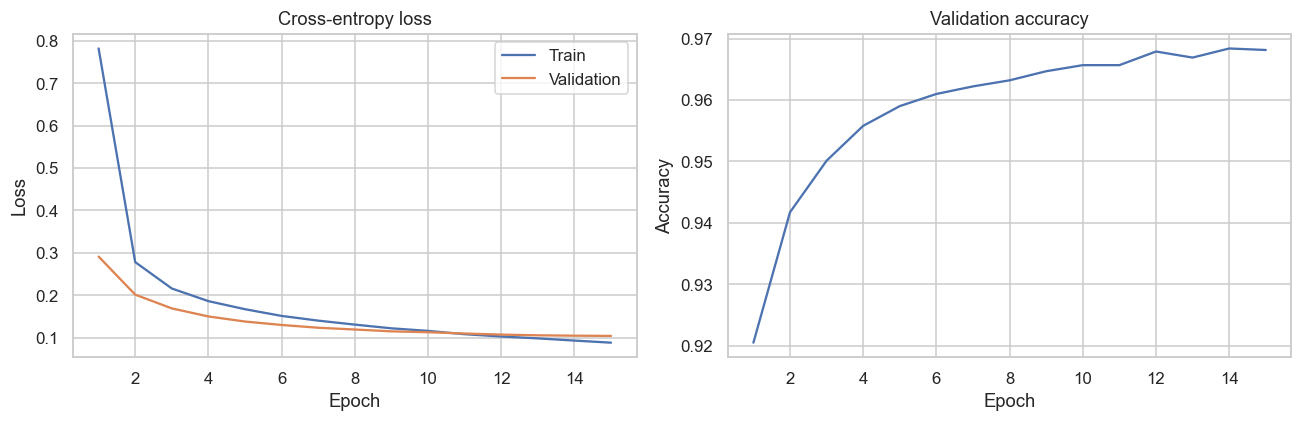

Best epoch: 14
Best validation accuracy: 0.9683950617283951


In [48]:
vision_history_table = pd.DataFrame(vision_history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(vision_history_table["epoch"], vision_history_table["train_loss"], label="Train")
axes[0].plot(vision_history_table["epoch"], vision_history_table["val_loss"], label="Validation")
axes[0].set(title="Cross-entropy loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].plot(vision_history_table["epoch"], vision_history_table["val_accuracy"])
axes[1].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
fig.tight_layout()
fig.savefig(EURO_DIR / "figures" / "training_curves.png", bbox_inches="tight")
plt.show()
vision_checkpoint = torch.load(EURO_DIR / "eurosat_best_model.pth", map_location="cpu", weights_only=True)
vision_model.load_state_dict(vision_checkpoint["model_state_dict"])
vision_model.eval()
print("Best epoch:", vision_checkpoint["best_epoch"])
print("Best validation accuracy:", vision_checkpoint["val_accuracy"])

### EuroSAT: Evaluate Test Data

test: loaded 4,050 cached frozen feature vectors


,Test
Accuracy,0.965926
Precision_macro,0.964641
Recall_macro,0.964756
F1_macro,0.964640
Precision_weighted,0.966026
Recall_weighted,0.965926
F1_weighted,0.965920


,precision,recall,f1-score,support
AnnualCrop,0.9524,0.9778,0.9649,450.0000
Forest,0.9821,0.9778,0.9800,450.0000
HerbaceousVegetation,0.9666,0.9644,0.9655,450.0000
Highway,0.9284,0.9333,0.9309,375.0000
Industrial,0.9736,0.9840,0.9788,375.0000
Pasture,0.9477,0.9667,0.9571,300.0000
PermanentCrop,0.9643,0.9360,0.9499,375.0000
Residential,0.9955,0.9844,0.9899,450.0000
River,0.9514,0.9387,0.9450,375.0000
SeaLake,0.9844,0.9844,0.9844,450.0000


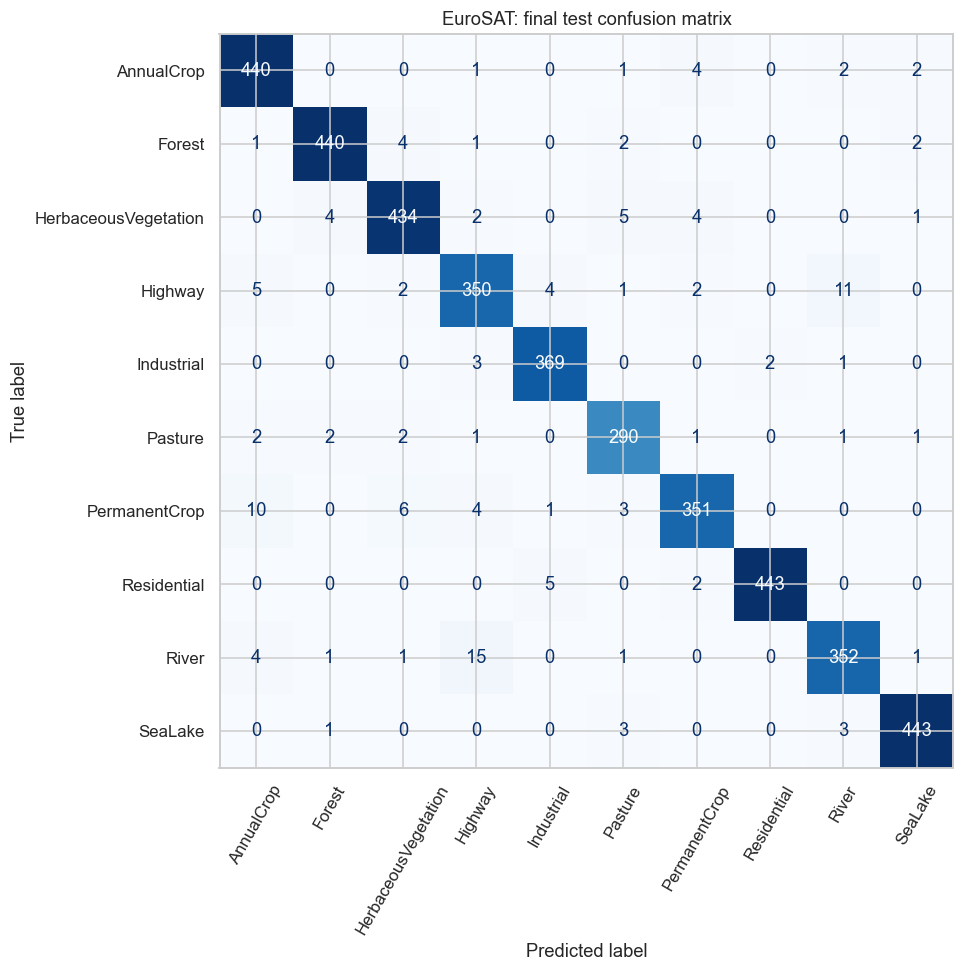

In [49]:
vision_test_features, vision_test_labels = extract_frozen_features(
    vision_backbone, vision_manifests["test"], vision_images, vision_cache, "test"
)
vision_test_loader = DataLoader(
    TensorDataset(vision_test_features, vision_test_labels), batch_size=256, shuffle=False
)
vision_test_loss, _, vision_true, vision_predicted = evaluate_vision_head(
    vision_model.classifier, vision_test_loader
)
vision_test_metrics = classification_metrics(vision_true, vision_predicted)
vision_test_report = pd.DataFrame(classification_report(
    vision_true, vision_predicted, labels=range(10), target_names=vision_classes,
    output_dict=True, zero_division=0
)).T
display(pd.Series(vision_test_metrics, name="Test").to_frame())
display(vision_test_report.round(4))
vision_test_report.to_csv(EURO_DIR / "test_classification_report.csv")
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(
    vision_true, vision_predicted, display_labels=vision_classes,
    xticks_rotation=60, cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("EuroSAT: final test confusion matrix")
fig.tight_layout()
fig.savefig(EURO_DIR / "figures" / "test_confusion_matrix.png", bbox_inches="tight")
plt.show()

### EuroSAT: Evaluate Suitability and Save Results

In [50]:
vision_binary_lookup = np.array([vision_suitability_map[name] for name in vision_classes])
vision_true_binary = vision_binary_lookup[vision_true]
vision_predicted_binary = vision_binary_lookup[vision_predicted]
vision_suitability_metrics = classification_metrics(vision_true_binary, vision_predicted_binary)
display(pd.Series(vision_suitability_metrics, name="Suitability proxy test").to_frame())
(EURO_DIR / "model_metrics.json").write_text(json.dumps({
    "multiclass_test": vision_test_metrics, "binary_suitability_test": vision_suitability_metrics,
    "test_loss": vision_test_loss, "best_epoch": vision_checkpoint["best_epoch"],
    "validation_accuracy": vision_checkpoint["val_accuracy"]
}, indent=2), encoding="utf-8")
pd.DataFrame({
    "image_id": vision_manifests["test"]["image_id"],
    "actual_class": vision_true, "predicted_class": vision_predicted,
    "actual_suitable": vision_true_binary, "predicted_suitable": vision_predicted_binary
}).to_csv(EURO_DIR / "test_predictions.csv", index=False)

,Suitability proxy test
Accuracy,0.987654
Precision_macro,0.986690
Recall_macro,0.987359
F1_macro,0.987022
Precision_weighted,0.987667
Recall_weighted,0.987654
F1_weighted,0.987659


### EuroSAT: Predict Land Suitability

In [51]:
def check_land_suitability(image_path):
    with Image.open(image_path) as image:
        tensor = training_image_transform(False)(image.convert("RGB")).unsqueeze(0)
    vision_model.eval()
    with torch.no_grad():
        probabilities = torch.softmax(vision_model(tensor), dim=1)[0]
    predicted_index = int(probabilities.argmax())
    predicted_class = vision_classes[predicted_index]
    suitable = bool(vision_suitability_map[predicted_class])
    decision = "أرض صالحة للزراعة (Suitable)" if suitable else "أرض غير صالحة للزراعة (Not Suitable)"
    print("الفئة المتوقعة:", predicted_class)
    print(decision)
    return {"predicted_class": predicted_class, "confidence": float(probabilities[predicted_index]),
            "suitable": suitable, "decision": decision}

### Soil: Load Training Data

In [52]:
soil_model_X = {}
soil_model_y = {}
for soil_name in ["train", "val", "test"]:
    soil_model_X[soil_name] = pd.read_csv(SOIL_DIR / f"X_{soil_name}.csv")
    soil_model_y[soil_name] = pd.read_csv(SOIL_DIR / f"y_{soil_name}.csv")["label"]
    assert len(soil_model_X[soil_name]) == len(soil_model_y[soil_name])
soil_saved_scaler = joblib.load(SOIL_DIR / "standard_scaler.joblib")
soil_saved_encoder = joblib.load(SOIL_DIR / "label_encoder.joblib")
soil_model_classes = soil_saved_encoder.classes_.tolist()
display(pd.DataFrame({
    "split": list(soil_model_X),
    "rows": [len(frame) for frame in soil_model_X.values()]
}))

,split,rows
0,train,1540
1,val,330
2,test,330


### Soil: Train and Compare Classifiers

In [53]:
soil_models = {
    "Random Forest": RandomForestClassifier(n_estimators=250, random_state=SEED, n_jobs=2),
    "XGBoost": XGBClassifier(n_estimators=250, max_depth=4, learning_rate=0.05,
                             tree_method="hist", random_state=SEED, n_jobs=2),
    "SVM": SVC(C=10, kernel="rbf", gamma="scale")
}
soil_comparison_rows = []
for soil_name, soil_model in soil_models.items():
    soil_model.fit(soil_model_X["train"], soil_model_y["train"])
    joblib.dump(soil_model, SOIL_DIR / "trained_models" / f"{soil_name.replace(' ', '_')}.joblib", compress=3)
    soil_prediction = soil_model.predict(soil_model_X["val"])
    soil_comparison_rows.append({
        "Model": soil_name, **classification_metrics(soil_model_y["val"], soil_prediction)
    })
soil_validation_table = pd.DataFrame(soil_comparison_rows).sort_values(
    ["Accuracy", "F1_macro"], ascending=False
).reset_index(drop=True)
soil_best_name = soil_validation_table.loc[0, "Model"]
display(soil_validation_table.round(5))
soil_validation_table.to_csv(SOIL_DIR / "validation_model_comparison.csv", index=False)
print("Model selected using validation:", soil_best_name)

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,Precision_weighted,Recall_weighted,F1_weighted
0,SVM,0.99394,0.99432,0.99394,0.99393,0.99432,0.99394,0.99393
1,Random Forest,0.99091,0.99148,0.99091,0.99090,0.99148,0.99091,0.99090
2,XGBoost,0.98788,0.98897,0.98788,0.98784,0.98897,0.98788,0.98784


Model selected using validation: SVM


### Soil: Tune Hyperparameters

In [54]:
soil_search_spaces = {
    "Random Forest": {
        "model__n_estimators": [150, 250, 400], "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2, 4], "model__max_features": ["sqrt", 0.8]
    },
    "XGBoost": {
        "model__n_estimators": [150, 250, 400], "model__max_depth": [3, 4, 6],
        "model__learning_rate": [0.03, 0.05, 0.1], "model__subsample": [0.8, 1.0]
    },
    "SVM": {"model__C": [1, 5, 10, 30, 100], "model__gamma": ["scale", 0.01, 0.1, 1.0]}
}
soil_search_pipeline = Pipeline([
    ("scale", StandardScaler()), ("model", clone(soil_models[soil_best_name]))
])
soil_original_train = pd.DataFrame(
    soil_saved_scaler.inverse_transform(soil_model_X["train"]),
    columns=soil_model_X["train"].columns
)
soil_search = RandomizedSearchCV(
    soil_search_pipeline, soil_search_spaces[soil_best_name], n_iter=8,
    scoring="f1_macro", cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=1, return_train_score=False
)
soil_search.fit(soil_original_train, soil_model_y["train"])
soil_tuned_model = clone(soil_search.best_estimator_.named_steps["model"])
soil_tuned_model.fit(soil_model_X["train"], soil_model_y["train"])
joblib.dump(soil_tuned_model, SOIL_DIR / "trained_models" / "tuned_candidate.joblib", compress=3)
pd.DataFrame(soil_search.cv_results_).to_csv(SOIL_DIR / "hyperparameter_search.csv", index=False)
display(pd.Series(soil_search.best_params_, name="Selected value").to_frame())
print("Best mean CV F1 macro:", soil_search.best_score_)

,Selected value
model__gamma,1.0
model__C,30.0


Best mean CV F1 macro: 0.9818400591100352


### Soil: Select Final Model

In [55]:
soil_candidates = {
    "Baseline": soil_models[soil_best_name],
    "Tuned": soil_tuned_model
}
soil_candidate_rows = []
for soil_variant, soil_model in soil_candidates.items():
    soil_pred = soil_model.predict(soil_model_X["val"])
    soil_candidate_rows.append({
        "Variant": soil_variant, **classification_metrics(soil_model_y["val"], soil_pred)
    })
soil_candidate_table = pd.DataFrame(soil_candidate_rows).sort_values(
    ["Accuracy", "F1_macro"], ascending=False
)
soil_final_variant = soil_candidate_table.iloc[0]["Variant"]
soil_final_model = soil_candidates[soil_final_variant]
soil_selection = {
    "model": soil_best_name, "variant": soil_final_variant,
    "selection_split": "validation", "test_used_for_selection": False,
    "best_search_parameters": soil_search.best_params_,
    "final_parameters": soil_final_model.get_params()
}
(SOIL_DIR / "model_selection.json").write_text(json.dumps(soil_selection, indent=2), encoding="utf-8")
display(soil_candidate_table.round(5))

,Variant,Accuracy,Precision_macro,Recall_macro,F1_macro,Precision_weighted,Recall_weighted,F1_weighted
0,Baseline,0.99394,0.99432,0.99394,0.99393,0.99432,0.99394,0.99393
1,Tuned,0.97879,0.97984,0.97879,0.97856,0.97984,0.97879,0.97856


### Soil: Evaluate and Save Final Model

,Test
Accuracy,0.990909
Precision_macro,0.991811
Recall_macro,0.990909
F1_macro,0.990879
Precision_weighted,0.991811
Recall_weighted,0.990909
F1_weighted,0.990879


,precision,recall,f1-score,support
apple,1.0000,1.0000,1.0000,15.0000
banana,1.0000,1.0000,1.0000,15.0000
blackgram,1.0000,1.0000,1.0000,15.0000
chickpea,1.0000,1.0000,1.0000,15.0000
coconut,1.0000,1.0000,1.0000,15.0000
coffee,1.0000,1.0000,1.0000,15.0000
cotton,0.9375,1.0000,0.9677,15.0000
grapes,1.0000,1.0000,1.0000,15.0000
jute,0.8824,1.0000,0.9375,15.0000
kidneybeans,1.0000,1.0000,1.0000,15.0000


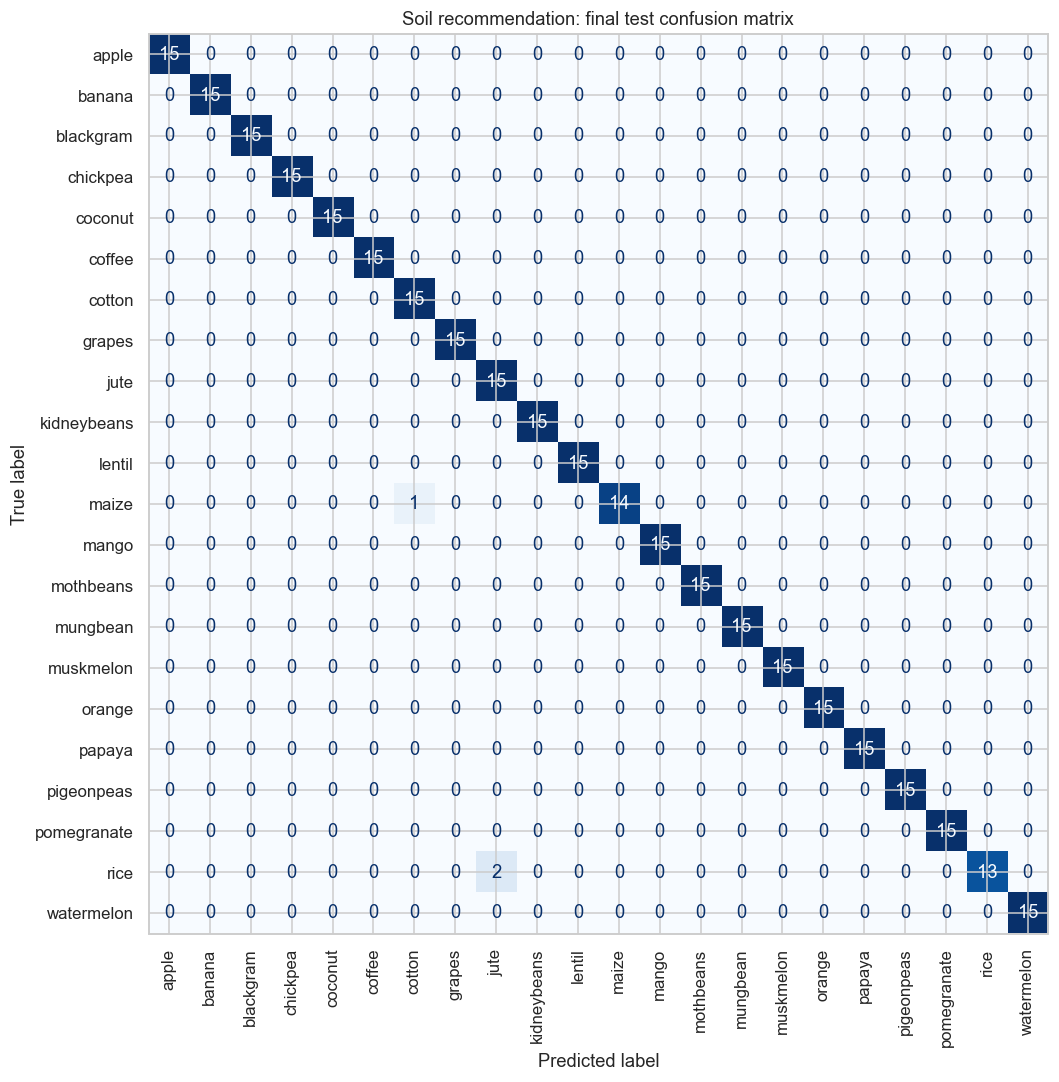

268

In [56]:
soil_test_prediction = soil_final_model.predict(soil_model_X["test"])
soil_final_metrics = classification_metrics(soil_model_y["test"], soil_test_prediction)
soil_test_report = pd.DataFrame(classification_report(
    soil_model_y["test"], soil_test_prediction, labels=range(22),
    target_names=soil_model_classes, output_dict=True, zero_division=0
)).T
display(pd.Series(soil_final_metrics, name="Test").to_frame())
display(soil_test_report.round(4))
soil_test_report.to_csv(SOIL_DIR / "test_classification_report.csv")
pd.DataFrame({"actual": soil_model_y["test"], "predicted": soil_test_prediction}).to_csv(
    SOIL_DIR / "test_predictions.csv", index=False
)
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    soil_model_y["test"], soil_test_prediction, display_labels=soil_model_classes,
    xticks_rotation=90, cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Soil recommendation: final test confusion matrix")
fig.tight_layout()
fig.savefig(SOIL_DIR / "figures" / "test_confusion_matrix.png", bbox_inches="tight")
plt.show()
joblib.dump(soil_final_model, SOIL_DIR / "soil_recommendation_model.joblib", compress=3)
joblib.dump({"model": soil_final_model, "scaler": soil_saved_scaler,
             "label_encoder": soil_saved_encoder, "features": soil_model_X["train"].columns.tolist()},
            SOIL_DIR / "soil_inference_bundle.joblib", compress=3)
(SOIL_DIR / "model_metrics.json").write_text(json.dumps(soil_final_metrics, indent=2), encoding="utf-8")

### India: Load Regression Data

In [57]:
yield_X = {}
yield_y = {}
yield_raw_targets = {}
for yield_split in ["train", "val", "test"]:
    yield_X[yield_split] = pd.read_csv(INDIA_DIR / f"X_{yield_split}.csv")
    yield_y[yield_split] = pd.read_csv(INDIA_DIR / f"y_{yield_split}.csv")["yield"]
    yield_raw_targets[yield_split] = pd.read_csv(INDIA_DIR / f"raw_targets_{yield_split}.csv")
    yield_manifest = pd.read_csv(INDIA_DIR / f"split_{yield_split}_manifest.csv")
    assert np.array_equal(yield_manifest["source_row_id"],
                          yield_raw_targets[yield_split]["source_row_id"])
    assert len(yield_X[yield_split]) == len(yield_y[yield_split])
yield_preprocessor = joblib.load(INDIA_DIR / "preprocessor.joblib")
yield_metadata = json.loads((INDIA_DIR / "metadata.json").read_text(encoding="utf-8"))
display(pd.DataFrame({
    "split": list(yield_X), "rows": [len(frame) for frame in yield_X.values()]
}))

,split,rows
0,train,170462
1,val,36528
2,test,36528


### India: Train and Compare Regressors

In [58]:
yield_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=160, max_depth=20,
                                            min_samples_leaf=2, random_state=SEED, n_jobs=2),
    "XGBoost": XGBRegressor(n_estimators=400, max_depth=6, learning_rate=0.05,
                            min_child_weight=3, tree_method="hist",
                            objective="reg:squarederror", random_state=SEED, n_jobs=2)
}
yield_validation_rows = []
for yield_name, yield_model in yield_models.items():
    yield_started = time.perf_counter()
    yield_model.fit(yield_X["train"], yield_y["train"])
    joblib.dump(yield_model, INDIA_DIR / "trained_models" / f"{yield_name.replace(' ', '_')}.joblib", compress=3)
    yield_prediction = yield_model.predict(yield_X["val"])
    yield_validation_rows.append({
        "Model": yield_name, **regression_metrics(yield_y["val"], yield_prediction)
    })
    print(yield_name, "training seconds:", round(time.perf_counter() - yield_started, 1), flush=True)
yield_validation_table = pd.DataFrame(yield_validation_rows).sort_values("RMSE")
yield_best_name = yield_validation_table.iloc[0]["Model"]
display(yield_validation_table.round(5))
yield_validation_table.to_csv(INDIA_DIR / "validation_model_comparison.csv", index=False)

Linear Regression training seconds: 0.1


Random Forest training seconds: 108.9


XGBoost training seconds: 6.0


,Model,RMSE,MAE,R2
1,Random Forest,0.58254,0.30891,0.88975
2,XGBoost,0.70408,0.42591,0.83894
0,Linear Regression,0.94548,0.60533,0.70957


### India: Prepare Cross-Validation Pipeline

In [59]:
yield_train_manifest = pd.read_csv(INDIA_DIR / "split_train_manifest.csv")
yield_prepared_train = pd.read_csv(INDIA_DIR / "prepared_train_audit.csv").set_index("source_row_id")
yield_original_train = yield_prepared_train.loc[
    yield_train_manifest["source_row_id"], yield_metadata["input_features"]
].copy()
yield_original_train.index = yield_X["train"].index
yield_fold_preprocessor = ColumnTransformer([
    ("target", TargetEncoder(target_type="continuous", cv=3, shuffle=True, random_state=SEED),
     ["state_name", "district_name", "crop"]),
    ("season", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["season"]),
    ("numeric", StandardScaler(), ["area", "crop_year"])
])
assert len(yield_original_train) == len(yield_y["train"])
display(yield_original_train.head())

,state_name,district_name,crop_year,season,crop,area
0,Uttar Pradesh,FARRUKHABAD,2004,Whole Year,Garlic,1084.0
1,Rajasthan,AJMER,2005,Kharif,Moth,2499.0
2,Chhattisgarh,BIJAPUR,2013,Rabi,Horse-gram,137.0
3,West Bengal,DARJEELING,2002,Whole Year,Arecanut,247.0
4,Himachal Pradesh,KINNAUR,2001,Whole Year,Potato,199.0


### India: Tune Hyperparameters

In [60]:
yield_search_spaces = {
    "Random Forest": {
        "model__n_estimators": [100, 160], "model__max_depth": [12, 18, 24],
        "model__min_samples_leaf": [2, 5], "model__max_features": [0.8, 1.0]
    },
    "XGBoost": {
        "model__n_estimators": [250, 400, 600], "model__max_depth": [4, 6, 8],
        "model__learning_rate": [0.03, 0.07, 0.1], "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0], "model__min_child_weight": [3, 10]
    },
    "Linear Regression": {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]}
}
yield_search_model = Ridge() if yield_best_name == "Linear Regression" else clone(yield_models[yield_best_name])
yield_search_pipeline = Pipeline([
    ("preprocess", yield_fold_preprocessor), ("model", yield_search_model)
])
yield_search = RandomizedSearchCV(
    yield_search_pipeline, yield_search_spaces[yield_best_name], n_iter=6,
    scoring="neg_root_mean_squared_error", cv=KFold(3, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=1, return_train_score=False, verbose=1
)
yield_tuning_indices = np.random.default_rng(SEED).choice(
    len(yield_original_train), size=min(50000, len(yield_original_train)), replace=False
)
yield_search_signature = hashlib.sha256(
    (INDIA_DIR / "X_train.csv").read_bytes() + (INDIA_DIR / "y_train.csv").read_bytes()
    + pd.util.hash_pandas_object(yield_original_train, index=False).to_numpy().tobytes()
    + json.dumps(yield_search_spaces[yield_best_name], sort_keys=True).encode()
    + f"{yield_best_name}:50000:6:3:42:target_cv3".encode()
).hexdigest()
yield_search_cache_path = INDIA_DIR / "hyperparameter_search_cache.json"
yield_search_cache = {}
if yield_search_cache_path.exists():
    yield_search_cache = json.loads(yield_search_cache_path.read_text(encoding="utf-8"))
if yield_search_cache.get("signature") == yield_search_signature:
    yield_best_parameters = yield_search_cache["parameters"]
    yield_best_cv_rmse = yield_search_cache["best_cv_rmse"]
    print("Reusing completed cross-validation results for matching training data and settings.")
else:
    yield_search.fit(yield_original_train.iloc[yield_tuning_indices],
                     yield_y["train"].iloc[yield_tuning_indices])
    yield_best_parameters = yield_search.best_params_
    yield_best_cv_rmse = -yield_search.best_score_
    pd.DataFrame(yield_search.cv_results_).to_csv(INDIA_DIR / "hyperparameter_search.csv", index=False)
    yield_search_cache = {"signature": yield_search_signature, "parameters": yield_best_parameters,
                          "best_cv_rmse": yield_best_cv_rmse, "tuning_rows": len(yield_tuning_indices)}
    yield_search_cache_path.write_text(json.dumps(yield_search_cache, indent=2), encoding="utf-8")
yield_model_parameters = {key.replace("model__", ""): value for key, value in yield_best_parameters.items()}
yield_tuned_model = clone(yield_search_model).set_params(**yield_model_parameters)
yield_tuned_model.fit(yield_X["train"], yield_y["train"])
joblib.dump(yield_tuned_model, INDIA_DIR / "trained_models" / "tuned_candidate.joblib", compress=3)
yield_train_manifest.iloc[yield_tuning_indices][["source_row_id"]].to_csv(
    INDIA_DIR / "hyperparameter_tuning_row_ids.csv", index=False)
display(pd.Series(yield_best_parameters, name="Selected value").to_frame())
print("Best mean CV RMSE:", yield_best_cv_rmse)

Reusing completed cross-validation results for matching training data and settings.


,Selected value
model__n_estimators,160.0
model__min_samples_leaf,2.0
model__max_features,0.8
model__max_depth,18.0


Best mean CV RMSE: 0.7544319952712123


### India: Select Final Model

In [61]:
yield_candidates = {"Baseline": yield_models[yield_best_name], "Tuned": yield_tuned_model}
yield_candidate_rows = []
for yield_variant, yield_model in yield_candidates.items():
    yield_prediction = yield_model.predict(yield_X["val"])
    yield_candidate_rows.append({
        "Variant": yield_variant, **regression_metrics(yield_y["val"], yield_prediction)
    })
yield_candidate_table = pd.DataFrame(yield_candidate_rows).sort_values("RMSE")
yield_final_variant = yield_candidate_table.iloc[0]["Variant"]
yield_final_model = yield_candidates[yield_final_variant]
yield_selection = {
    "model": yield_best_name, "variant": yield_final_variant,
    "selection_split": "validation", "test_used_for_selection": False,
    "search_parameters": yield_best_parameters,
    "tuning_rows": len(yield_tuning_indices), "final_training_rows": len(yield_X["train"]),
    "final_parameters": yield_final_model.get_params()
}
(INDIA_DIR / "model_selection.json").write_text(json.dumps(yield_selection, indent=2), encoding="utf-8")
display(yield_candidate_table.round(5))

,Variant,RMSE,MAE,R2
1,Tuned,0.57828,0.31520,0.89136
0,Baseline,0.58254,0.30891,0.88975


### India: Evaluate Validation and Test Data

In [62]:
yield_evaluation_models = {**yield_models, "Final selected": yield_final_model}
yield_evaluation_rows = []
for yield_name, yield_model in yield_evaluation_models.items():
    for yield_split in ["val", "test"]:
        yield_prediction = yield_model.predict(yield_X[yield_split])
        yield_evaluation_rows.append({
            "Model": yield_name, "Split": yield_split,
            **regression_metrics(yield_y[yield_split], yield_prediction)
        })
yield_evaluation_table = pd.DataFrame(yield_evaluation_rows)
display(yield_evaluation_table.round(5))
yield_evaluation_table.to_csv(INDIA_DIR / "model_evaluation.csv", index=False)
yield_test_prediction = yield_final_model.predict(yield_X["test"])
yield_final_metrics = regression_metrics(yield_y["test"], yield_test_prediction)

,Model,Split,RMSE,MAE,R2
0,Linear Regression,val,0.94548,0.60533,0.70957
1,Linear Regression,test,0.94228,0.60159,0.70990
2,Random Forest,val,0.58254,0.30891,0.88975
3,Random Forest,test,0.58339,0.30883,0.88880
4,XGBoost,val,0.70408,0.42591,0.83894
5,XGBoost,test,0.70218,0.42278,0.83891
6,Final selected,val,0.57828,0.31520,0.89136
7,Final selected,test,0.57801,0.31413,0.89084


### India: Save Yield Model and Results

In [63]:
yield_observed_mask = yield_raw_targets["test"]["target_observed"].astype(bool).to_numpy()
assert np.array_equal(yield_observed_mask, yield_raw_targets["test"]["production_raw"].notna())
yield_observed_metrics = regression_metrics(
    yield_y["test"][yield_observed_mask], yield_test_prediction[yield_observed_mask]
)
yield_original_metrics = regression_metrics(
    yield_raw_targets["test"].loc[yield_observed_mask, "yield_observed"],
    yield_test_prediction[yield_observed_mask]
)
yield_target_audit = pd.DataFrame([
    {"Target": "Clipped, all test rows", **yield_final_metrics},
    {"Target": "Clipped, observed rows only", **yield_observed_metrics},
    {"Target": "Original yield, observed rows only", **yield_original_metrics}
])
yield_target_audit.to_csv(INDIA_DIR / "observed_target_evaluation.csv", index=False)

joblib.dump(yield_final_model, INDIA_DIR / "yield_prediction_model.joblib", compress=3)
joblib.dump({
    "model": yield_final_model, "preprocessor": yield_preprocessor,
    "cleaning_parameters": joblib.load(INDIA_DIR / "cleaning_parameters.joblib"),
    "input_features": yield_metadata["input_features"],
    "output_features": yield_X["train"].columns.tolist()
}, INDIA_DIR / "yield_inference_bundle.joblib", compress=3)
yield_predictions_table = pd.DataFrame({
    "source_row_id": yield_raw_targets["test"]["source_row_id"],
    "actual_clipped": yield_y["test"], "predicted": yield_test_prediction,
    "target_observed": yield_observed_mask,
    "actual_original": yield_raw_targets["test"]["yield_observed"]
})
yield_predictions_table.to_csv(INDIA_DIR / "test_predictions.csv", index=False)
(INDIA_DIR / "model_metrics.json").write_text(json.dumps({
    "test_clipped_all": yield_final_metrics, "test_clipped_observed": yield_observed_metrics,
    "test_original_observed": yield_original_metrics
}, indent=2), encoding="utf-8")

378